### Business problem: Companies need to understand why orders are delayed, which products and regions generate profit, and where logistics costs are increasing.

In [72]:
## Importing libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math



In [73]:
# Loading the dataset
df = pd.read_csv(r"C:\Users\Rahul\Desktop\Data_SCM\SupplySight\data\DataCoSupplyChainDataset.csv",encoding="cp1252")

In [74]:
# Load the head of the dataset
df.head(10)

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class
5,TRANSFER,6,4,18.580000,294.980011,Shipping canceled,0,73,Sporting Goods,Tonawanda,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/19/2018 11:03,Standard Class
6,DEBIT,2,1,95.180000,288.420013,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 10:42,First Class
7,TRANSFER,2,1,68.430000,285.140015,Late delivery,1,73,Sporting Goods,Miami,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 10:21,First Class
8,CASH,3,2,133.720001,278.589996,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 10:00,Second Class
9,CASH,2,1,132.149994,275.309998,Late delivery,1,73,Sporting Goods,San Ramon,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 9:39,First Class


In [75]:
print("The columns in the dataset are:",df.columns)
print("The Number of columns in the dataset:",len(df.columns))

The columns in the dataset are: Index(['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)',
       'Benefit per order', 'Sales per customer', 'Delivery Status',
       'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City',
       'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id',
       'Customer Lname', 'Customer Password', 'Customer Segment',
       'Customer State', 'Customer Street', 'Customer Zipcode',
       'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market',
       'Order City', 'Order Country', 'Order Customer Id',
       'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id',
       'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id',
       'Order Item Product Price', 'Order Item Profit Ratio',
       'Order Item Quantity', 'Sales', 'Order Item Total',
       'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status',
       'Order Zipcode', 'Product Card Id', 'Product 

In [76]:
print("The Information about the columns: \n",df.info())
print("Describe the columns: \n",df.describe)

<class 'pandas.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  str    
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  str    
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  str    
 9   Customer City                  180519 non-null  str    
 10  Customer Country               180519 non-null  str    
 11  Customer Email                 180519 non-null  str    
 12  Customer Fname                 180519 non

In [77]:
# Finding out Missing values and duplicates from the dataset

print("Missing rows from the columns:\n",df.isnull().sum())

Missing rows from the columns:
 Type                                  0
Days for shipping (real)              0
Days for shipment (scheduled)         0
Benefit per order                     0
Sales per customer                    0
Delivery Status                       0
Late_delivery_risk                    0
Category Id                           0
Category Name                         0
Customer City                         0
Customer Country                      0
Customer Email                        0
Customer Fname                        0
Customer Id                           0
Customer Lname                        8
Customer Password                     0
Customer Segment                      0
Customer State                        0
Customer Street                       0
Customer Zipcode                      3
Department Id                         0
Department Name                       0
Latitude                              0
Longitude                             0
Market  

#### Missing Columns: 
- Customer Lname                        8
- Customer Zipcode                      3
- Order Zipcode                    155679
- Product Description              180519

In [78]:
# Unique Rows to the columns/duplicates
print("The Duplicate rows in the Dataset:\n",df.duplicated().sum())
print("Unique rows in the Dataset:\n",df.nunique().sum())


The Duplicate rows in the Dataset:
 0
Unique rows in the Dataset:
 501288


### No duplicates but missing value that will be removed.
- Customer LName and customer zipcode only few so rows will be removed.
- Order Zipcode and Product description almost all missing especially product description, Hence Column will be removed entirely.


In [79]:
# Dropping missing columns

df_new=df.drop(columns=['Product Description','Order Zipcode'])
df_new

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order State,Order Status,Product Card Id,Product Category Id,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,Java Occidental,COMPLETE,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,Rajastán,PENDING,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,Rajastán,CLOSED,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,Queensland,COMPLETE,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,Queensland,PENDING_PAYMENT,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,1/15/2018 11:24,Standard Class
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
180514,CASH,4,4,40.000000,399.980011,Shipping on time,0,45,Fishing,Brooklyn,...,Shanghái,CLOSED,1004,45,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/20/2016 3:40,Standard Class
180515,DEBIT,3,2,-613.770019,395.980011,Late delivery,1,45,Fishing,Bakersfield,...,Osaka,COMPLETE,1004,45,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/19/2016 1:34,Second Class
180516,TRANSFER,5,4,141.110001,391.980011,Late delivery,1,45,Fishing,Bristol,...,Australia del Sur,PENDING,1004,45,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/20/2016 21:00,Standard Class
180517,PAYMENT,3,4,186.229996,387.980011,Advance shipping,0,45,Fishing,Caguas,...,Australia del Sur,PENDING_PAYMENT,1004,45,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/18/2016 20:18,Standard Class


In [80]:
# Dropping missing rows 

df_new.dropna(subset=['Customer Lname','Customer Zipcode'],inplace=True)
df_new

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order State,Order Status,Product Card Id,Product Category Id,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,Java Occidental,COMPLETE,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,Rajastán,PENDING,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,Rajastán,CLOSED,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,Queensland,COMPLETE,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,Queensland,PENDING_PAYMENT,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,1/15/2018 11:24,Standard Class
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
180514,CASH,4,4,40.000000,399.980011,Shipping on time,0,45,Fishing,Brooklyn,...,Shanghái,CLOSED,1004,45,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/20/2016 3:40,Standard Class
180515,DEBIT,3,2,-613.770019,395.980011,Late delivery,1,45,Fishing,Bakersfield,...,Osaka,COMPLETE,1004,45,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/19/2016 1:34,Second Class
180516,TRANSFER,5,4,141.110001,391.980011,Late delivery,1,45,Fishing,Bristol,...,Australia del Sur,PENDING,1004,45,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/20/2016 21:00,Standard Class
180517,PAYMENT,3,4,186.229996,387.980011,Advance shipping,0,45,Fishing,Caguas,...,Australia del Sur,PENDING_PAYMENT,1004,45,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/18/2016 20:18,Standard Class


### Dropping columns that hold no significance or add value to the objectives

In [81]:
# Columns not needed
cols = [
    'Category Id',
    'Customer Country',
    'Customer Email',
    'Customer Fname',
    'Customer Id',
    'Customer Lname',
    'Customer Password',
    'Customer Zipcode',
    'Department Id',
    'Latitude',
    'Longitude',
    'Order Customer Id',
    'Order Item Cardprod Id',
    'Order Item Id',
    'Product Card Id',
    'Product Category Id',
    'Product Image',
    'Product Status'
]

# Dropping cols not needed
df_new.drop(columns=cols,inplace=True)
df_new

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Name,Customer City,Customer Segment,...,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Product Name,Product Price,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,Sporting Goods,Caguas,Consumer,...,327.750000,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,Smart watch,327.750000,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,Sporting Goods,Caguas,Consumer,...,327.750000,311.359985,-249.089996,South Asia,Rajastán,PENDING,Smart watch,327.750000,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,Sporting Goods,San Jose,Consumer,...,327.750000,309.720001,-247.779999,South Asia,Rajastán,CLOSED,Smart watch,327.750000,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,Sporting Goods,Los Angeles,Home Office,...,327.750000,304.809998,22.860001,Oceania,Queensland,COMPLETE,Smart watch,327.750000,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,Sporting Goods,Caguas,Corporate,...,327.750000,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,Smart watch,327.750000,1/15/2018 11:24,Standard Class
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
180514,CASH,4,4,40.000000,399.980011,Shipping on time,0,Fishing,Brooklyn,Home Office,...,399.980011,399.980011,40.000000,Eastern Asia,Shanghái,CLOSED,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,1/20/2016 3:40,Standard Class
180515,DEBIT,3,2,-613.770019,395.980011,Late delivery,1,Fishing,Bakersfield,Corporate,...,399.980011,395.980011,-613.770019,Eastern Asia,Osaka,COMPLETE,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,1/19/2016 1:34,Second Class
180516,TRANSFER,5,4,141.110001,391.980011,Late delivery,1,Fishing,Bristol,Corporate,...,399.980011,391.980011,141.110001,Oceania,Australia del Sur,PENDING,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,1/20/2016 21:00,Standard Class
180517,PAYMENT,3,4,186.229996,387.980011,Advance shipping,0,Fishing,Caguas,Consumer,...,399.980011,387.980011,186.229996,Oceania,Australia del Sur,PENDING_PAYMENT,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,1/18/2016 20:18,Standard Class


In [82]:
df_new.info()

<class 'pandas.DataFrame'>
Index: 180508 entries, 0 to 180518
Data columns (total 33 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180508 non-null  str    
 1   Days for shipping (real)       180508 non-null  int64  
 2   Days for shipment (scheduled)  180508 non-null  int64  
 3   Benefit per order              180508 non-null  float64
 4   Sales per customer             180508 non-null  float64
 5   Delivery Status                180508 non-null  str    
 6   Late_delivery_risk             180508 non-null  int64  
 7   Category Name                  180508 non-null  str    
 8   Customer City                  180508 non-null  str    
 9   Customer Segment               180508 non-null  str    
 10  Customer State                 180508 non-null  str    
 11  Customer Street                180508 non-null  str    
 12  Department Name                180508 non-null

In [83]:
# Now we turn dates into date type from str

df_new['order date (DateOrders)'] = pd.to_datetime(df_new['order date (DateOrders)'])
df_new['shipping date (DateOrders)'] = pd.to_datetime(df_new['shipping date (DateOrders)'])


df_new

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Name,Customer City,Customer Segment,...,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Product Name,Product Price,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,Sporting Goods,Caguas,Consumer,...,327.750000,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,Smart watch,327.750000,2018-02-03 22:56:00,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,Sporting Goods,Caguas,Consumer,...,327.750000,311.359985,-249.089996,South Asia,Rajastán,PENDING,Smart watch,327.750000,2018-01-18 12:27:00,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,Sporting Goods,San Jose,Consumer,...,327.750000,309.720001,-247.779999,South Asia,Rajastán,CLOSED,Smart watch,327.750000,2018-01-17 12:06:00,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,Sporting Goods,Los Angeles,Home Office,...,327.750000,304.809998,22.860001,Oceania,Queensland,COMPLETE,Smart watch,327.750000,2018-01-16 11:45:00,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,Sporting Goods,Caguas,Corporate,...,327.750000,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,Smart watch,327.750000,2018-01-15 11:24:00,Standard Class
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
180514,CASH,4,4,40.000000,399.980011,Shipping on time,0,Fishing,Brooklyn,Home Office,...,399.980011,399.980011,40.000000,Eastern Asia,Shanghái,CLOSED,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,2016-01-20 03:40:00,Standard Class
180515,DEBIT,3,2,-613.770019,395.980011,Late delivery,1,Fishing,Bakersfield,Corporate,...,399.980011,395.980011,-613.770019,Eastern Asia,Osaka,COMPLETE,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,2016-01-19 01:34:00,Second Class
180516,TRANSFER,5,4,141.110001,391.980011,Late delivery,1,Fishing,Bristol,Corporate,...,399.980011,391.980011,141.110001,Oceania,Australia del Sur,PENDING,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,2016-01-20 21:00:00,Standard Class
180517,PAYMENT,3,4,186.229996,387.980011,Advance shipping,0,Fishing,Caguas,Consumer,...,399.980011,387.980011,186.229996,Oceania,Australia del Sur,PENDING_PAYMENT,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,2016-01-18 20:18:00,Standard Class


In [84]:
# Checking for similar cols 

mapping1 = df_new['Sales per customer'] == df_new['Order Item Total']
mapping1.sum()

np.int64(180508)

In [85]:
# Thus we can remove one that is redundant column

df_new.drop(columns=['Order Item Total'],inplace=True)
df_new

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Name,Customer City,Customer Segment,...,Order Item Quantity,Sales,Order Profit Per Order,Order Region,Order State,Order Status,Product Name,Product Price,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,Sporting Goods,Caguas,Consumer,...,1,327.750000,91.250000,Southeast Asia,Java Occidental,COMPLETE,Smart watch,327.750000,2018-02-03 22:56:00,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,Sporting Goods,Caguas,Consumer,...,1,327.750000,-249.089996,South Asia,Rajastán,PENDING,Smart watch,327.750000,2018-01-18 12:27:00,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,Sporting Goods,San Jose,Consumer,...,1,327.750000,-247.779999,South Asia,Rajastán,CLOSED,Smart watch,327.750000,2018-01-17 12:06:00,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,Sporting Goods,Los Angeles,Home Office,...,1,327.750000,22.860001,Oceania,Queensland,COMPLETE,Smart watch,327.750000,2018-01-16 11:45:00,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,Sporting Goods,Caguas,Corporate,...,1,327.750000,134.210007,Oceania,Queensland,PENDING_PAYMENT,Smart watch,327.750000,2018-01-15 11:24:00,Standard Class
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
180514,CASH,4,4,40.000000,399.980011,Shipping on time,0,Fishing,Brooklyn,Home Office,...,1,399.980011,40.000000,Eastern Asia,Shanghái,CLOSED,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,2016-01-20 03:40:00,Standard Class
180515,DEBIT,3,2,-613.770019,395.980011,Late delivery,1,Fishing,Bakersfield,Corporate,...,1,399.980011,-613.770019,Eastern Asia,Osaka,COMPLETE,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,2016-01-19 01:34:00,Second Class
180516,TRANSFER,5,4,141.110001,391.980011,Late delivery,1,Fishing,Bristol,Corporate,...,1,399.980011,141.110001,Oceania,Australia del Sur,PENDING,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,2016-01-20 21:00:00,Standard Class
180517,PAYMENT,3,4,186.229996,387.980011,Advance shipping,0,Fishing,Caguas,Consumer,...,1,399.980011,186.229996,Oceania,Australia del Sur,PENDING_PAYMENT,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,2016-01-18 20:18:00,Standard Class


In [86]:
# Similar cols mapping and removal
mappings2 = df_new['Benefit per order'] == df_new['Order Profit Per Order']
mappings2.sum()

mappings3 = df_new['Product Price'] == df_new['Order Item Product Price']
mappings3.sum()

df_new.drop(columns=['Order Profit Per Order','Order Item Product Price'],inplace=True)
df_new

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Name,Customer City,Customer Segment,...,Order Item Profit Ratio,Order Item Quantity,Sales,Order Region,Order State,Order Status,Product Name,Product Price,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,Sporting Goods,Caguas,Consumer,...,0.29,1,327.750000,Southeast Asia,Java Occidental,COMPLETE,Smart watch,327.750000,2018-02-03 22:56:00,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,Sporting Goods,Caguas,Consumer,...,-0.80,1,327.750000,South Asia,Rajastán,PENDING,Smart watch,327.750000,2018-01-18 12:27:00,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,Sporting Goods,San Jose,Consumer,...,-0.80,1,327.750000,South Asia,Rajastán,CLOSED,Smart watch,327.750000,2018-01-17 12:06:00,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,Sporting Goods,Los Angeles,Home Office,...,0.08,1,327.750000,Oceania,Queensland,COMPLETE,Smart watch,327.750000,2018-01-16 11:45:00,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,Sporting Goods,Caguas,Corporate,...,0.45,1,327.750000,Oceania,Queensland,PENDING_PAYMENT,Smart watch,327.750000,2018-01-15 11:24:00,Standard Class
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
180514,CASH,4,4,40.000000,399.980011,Shipping on time,0,Fishing,Brooklyn,Home Office,...,0.10,1,399.980011,Eastern Asia,Shanghái,CLOSED,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,2016-01-20 03:40:00,Standard Class
180515,DEBIT,3,2,-613.770019,395.980011,Late delivery,1,Fishing,Bakersfield,Corporate,...,-1.55,1,399.980011,Eastern Asia,Osaka,COMPLETE,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,2016-01-19 01:34:00,Second Class
180516,TRANSFER,5,4,141.110001,391.980011,Late delivery,1,Fishing,Bristol,Corporate,...,0.36,1,399.980011,Oceania,Australia del Sur,PENDING,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,2016-01-20 21:00:00,Standard Class
180517,PAYMENT,3,4,186.229996,387.980011,Advance shipping,0,Fishing,Caguas,Consumer,...,0.48,1,399.980011,Oceania,Australia del Sur,PENDING_PAYMENT,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,2016-01-18 20:18:00,Standard Class


### Outlier Detection

In [87]:
# We will first seperate both the cols into numerical and categorical

numerical_cols = df_new.select_dtypes(include=[np.int64,np.float64]).columns.to_list()
categorical_cols = df_new.select_dtypes(include=['object','category']).columns.to_list()

print("THe Numerical cols in the above dataset are:\n",numerical_cols)
print("The Categorical cols in the above dataset are:\n",categorical_cols)

THe Numerical cols in the above dataset are:
 ['Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Late_delivery_risk', 'Order Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Product Price']
The Categorical cols in the above dataset are:
 ['Type', 'Delivery Status', 'Category Name', 'Customer City', 'Customer Segment', 'Customer State', 'Customer Street', 'Department Name', 'Market', 'Order City', 'Order Country', 'Order Region', 'Order State', 'Order Status', 'Product Name', 'Shipping Mode']


C:\Users\Rahul\AppData\Local\Temp\ipykernel_34056\3649115734.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df_new.select_dtypes(include=['object','category']).columns.to_list()


In [88]:
numerical_cols


['Days for shipping (real)',
 'Days for shipment (scheduled)',
 'Benefit per order',
 'Sales per customer',
 'Late_delivery_risk',
 'Order Id',
 'Order Item Discount',
 'Order Item Discount Rate',
 'Order Item Profit Ratio',
 'Order Item Quantity',
 'Sales',
 'Product Price']

In [89]:
categorical_cols

['Type',
 'Delivery Status',
 'Category Name',
 'Customer City',
 'Customer Segment',
 'Customer State',
 'Customer Street',
 'Department Name',
 'Market',
 'Order City',
 'Order Country',
 'Order Region',
 'Order State',
 'Order Status',
 'Product Name',
 'Shipping Mode']

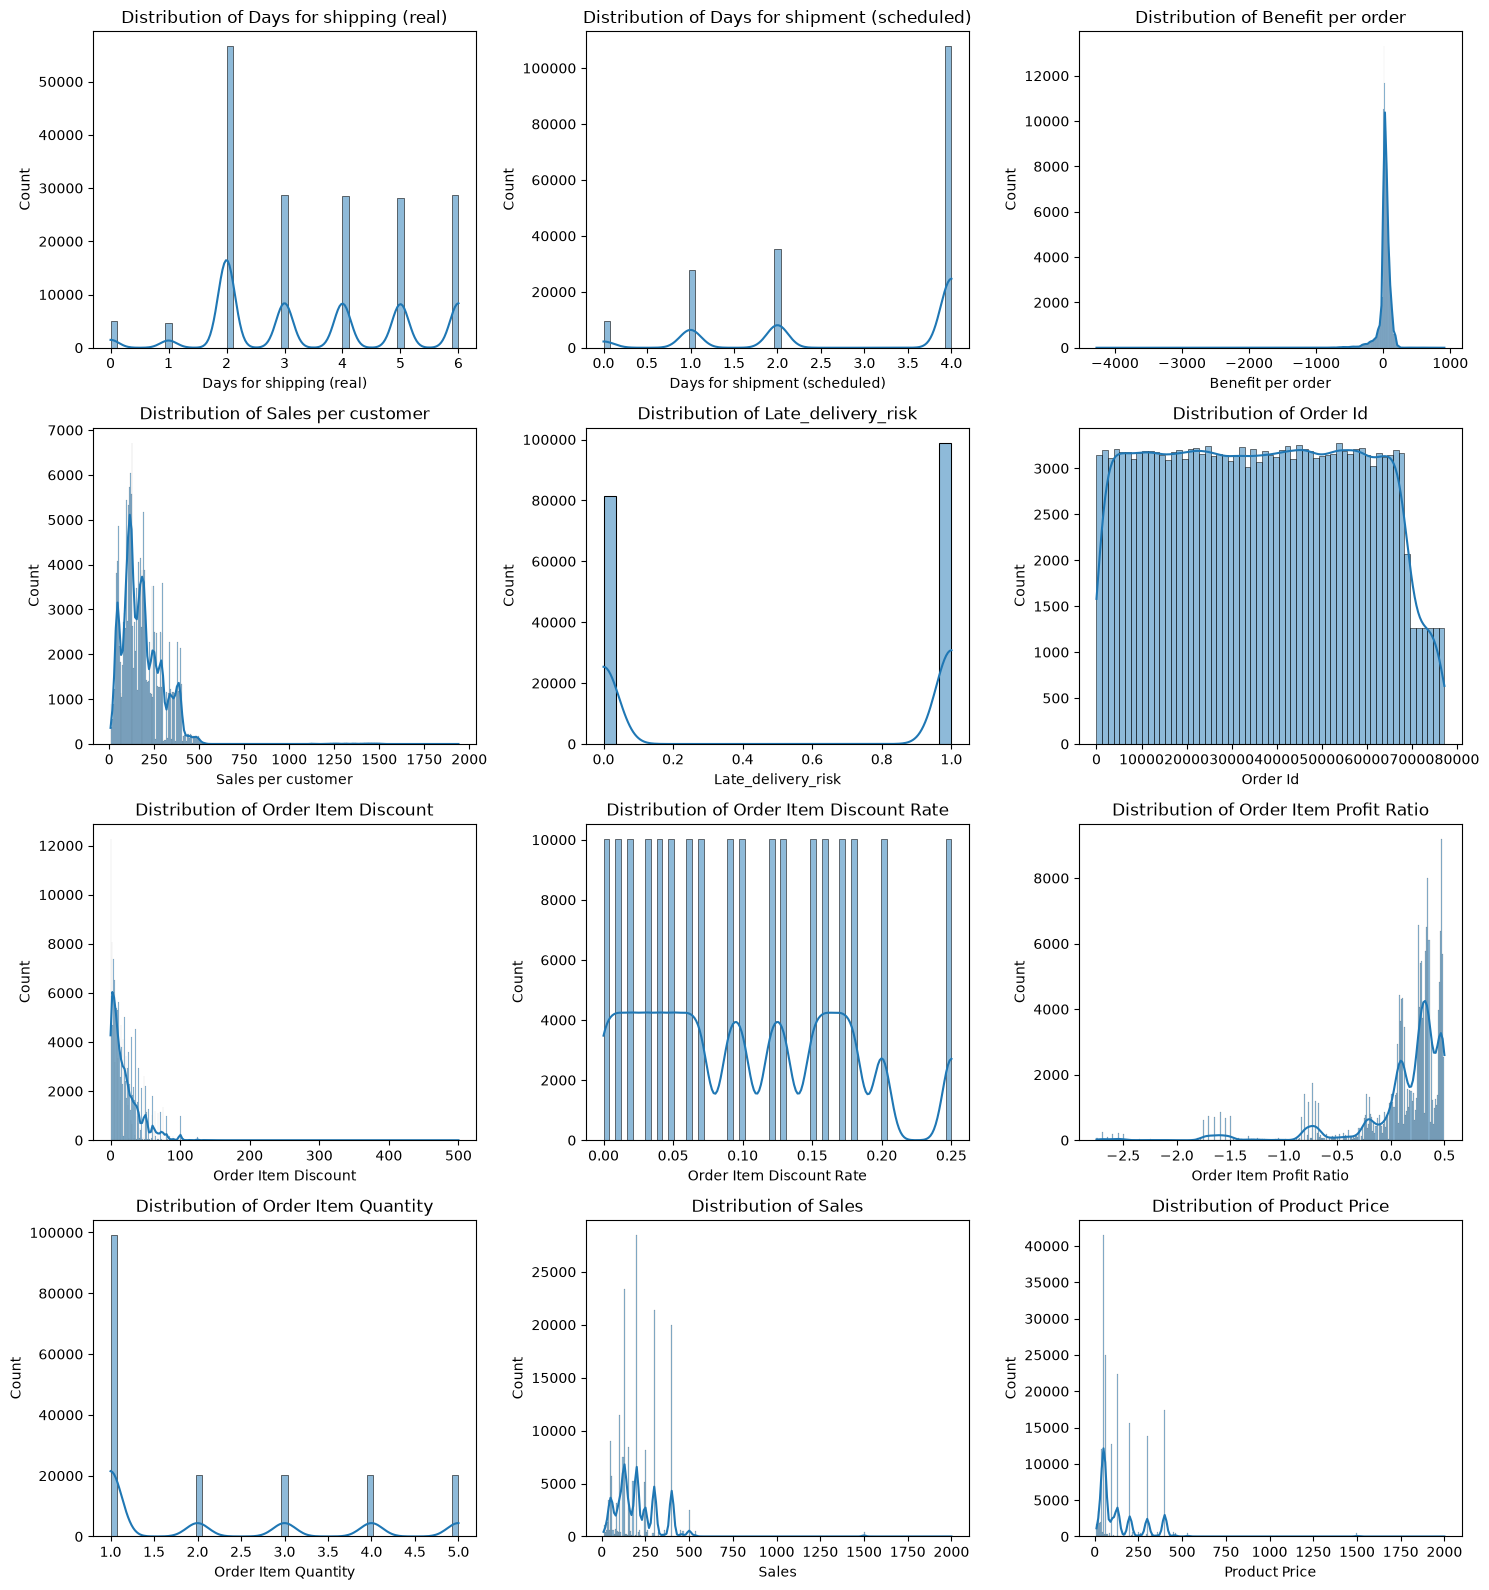

In [90]:
# Vizualsiing the numerical_cols 
n_cols = 3
n_rows = math.ceil(len(numerical_cols)/n_cols)

plt.figure(figsize=(15,4*n_rows))
for i,col in enumerate(numerical_cols):
	plt.subplot(n_rows,n_cols,i+1)
	sns.histplot(data=df_new, x=col, kde=True)
	plt.title(f'Distribution of {col}')
plt.tight_layout()
plt.show()
	

#### Columns for Outlier Detection Using IQR
- Benifit Per Order
- Sales Per Customer
- Order Item Discount
- Order Item Profit Ratio
- Sales
- Product Price

In [91]:
iqr_cols = ['Benefit per order','Sales per customer','Order Item Discount','Order Item Profit Ratio','Sales','Product Price']

outlier_summary = []

for i,col in enumerate(iqr_cols):

    q1 = df_new[col].quantile(0.25)
    q3 = df_new[col].quantile(0.75)

    iqr = q3 - q1

    # Calculating upper and lower bound
    lower_bound = q1-1.5*iqr
    upper_bound = q3+1.5*iqr

    # Counting the outlier 

    outlier_count = ((df_new[col] < lower_bound) | (df_new[col] > upper_bound)).sum()
    outlier_percentage = round((outlier_count)/len(df_new)*100,2)

    outlier_summary.append({
        "Column": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": outlier_count,
        "Outlier_Percentage": f"{outlier_percentage}%"
    })

outlier_summary1 = pd.DataFrame(outlier_summary)
print(outlier_summary1)




                    Column          Q1          Q3         IQR  Lower_Bound  \
0        Benefit per order    7.000000   64.800003   57.800003   -79.700005   
1       Sales per customer  104.379997  247.399994  143.019997  -110.149998   
2      Order Item Discount    5.400000   29.990000   24.590000   -31.484999   
3  Order Item Profit Ratio    0.080000    0.360000    0.280000    -0.340000   
4                    Sales  119.980003  299.950012  179.970009  -149.975010   
5            Product Price   50.000000  199.990005  149.990005  -174.985008   

   Upper_Bound  Outlier_Count Outlier_Percentage  
0   151.500008          18938             10.49%  
1   461.929989           1943              1.08%  
2    66.874999           7537              4.18%  
3     0.780000          17300              9.58%  
4   569.905025            488              0.27%  
5   424.975014           2045              1.13%  


#### There is no actual need for removal as these are buisness anamolies that will help us explain customer behaviour and thus we will only cap the above dataset to upper / lower bound

### Univariate Analysis

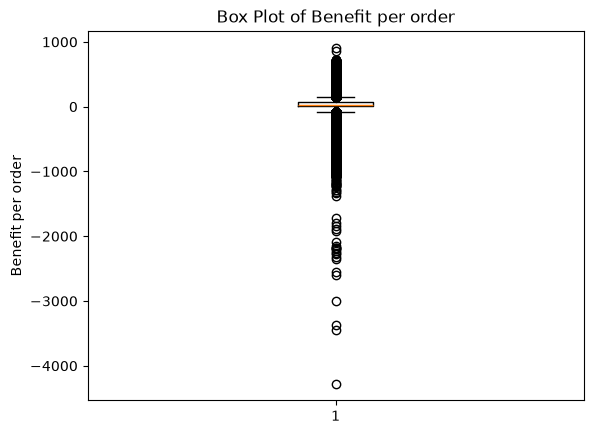

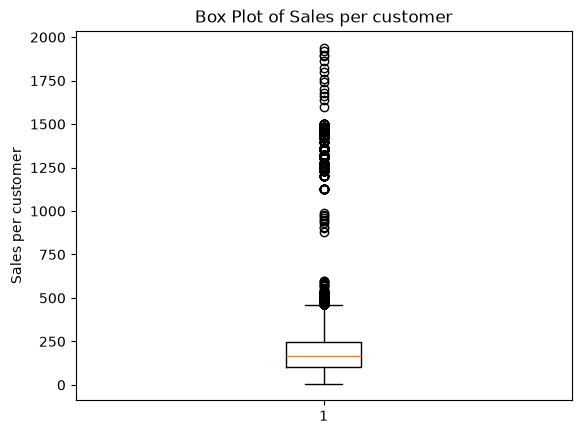

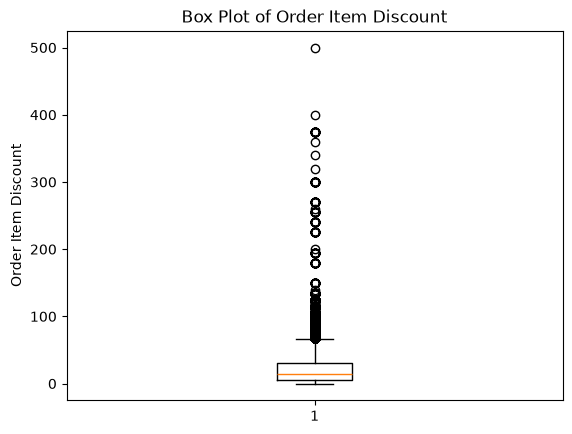

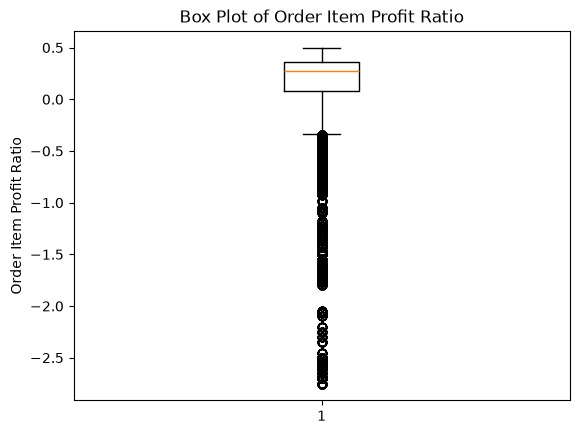

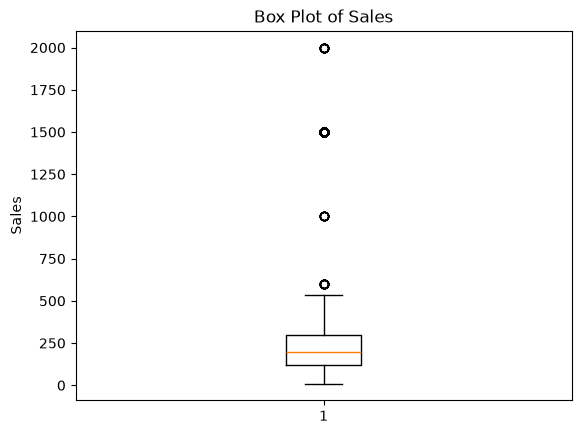

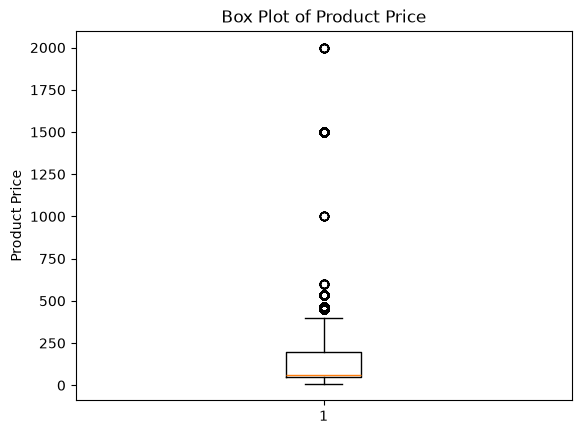

In [92]:
# Outlier Distribution

for col in iqr_cols:
    plt.boxplot(df_new[col])
    plt.title(f"Box Plot of {col}")
    plt.ylabel(col)
    plt.show()

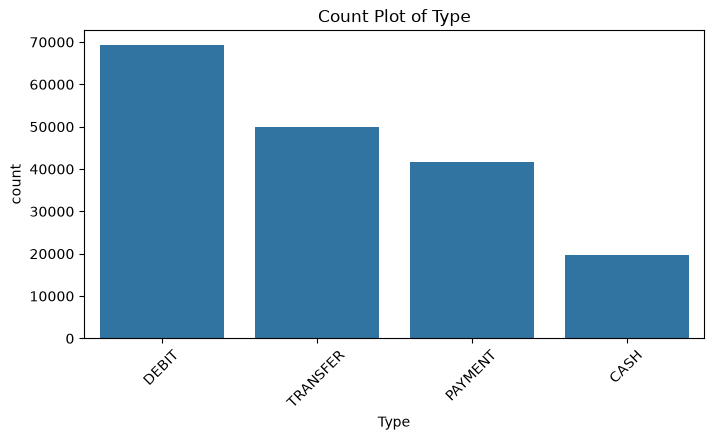

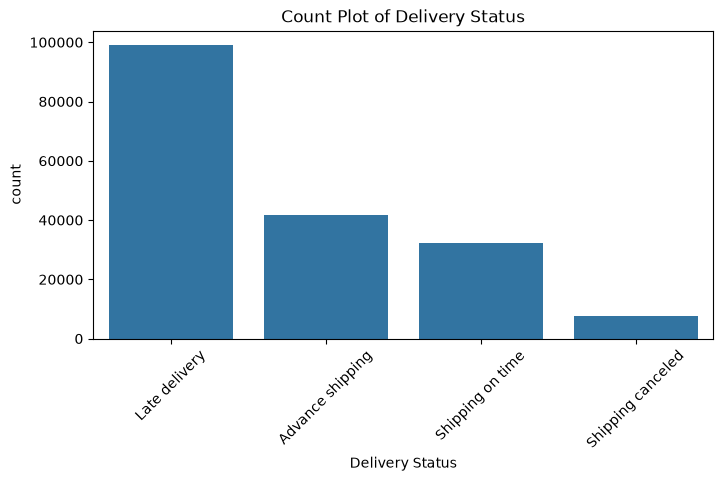

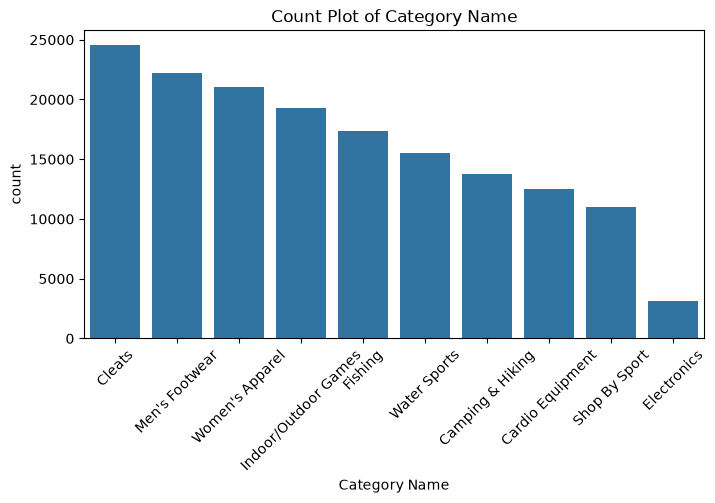

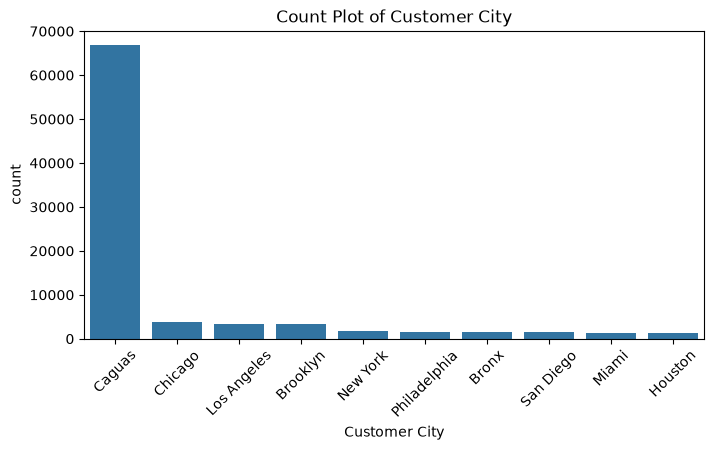

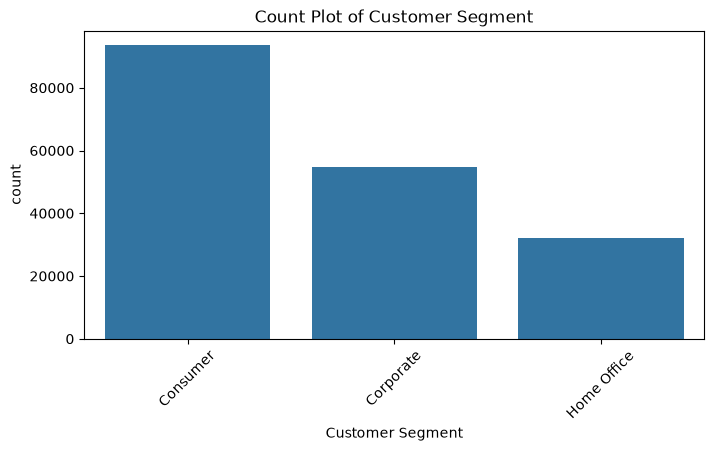

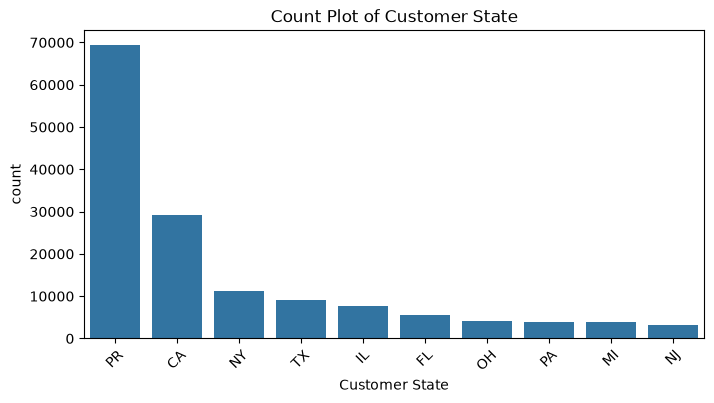

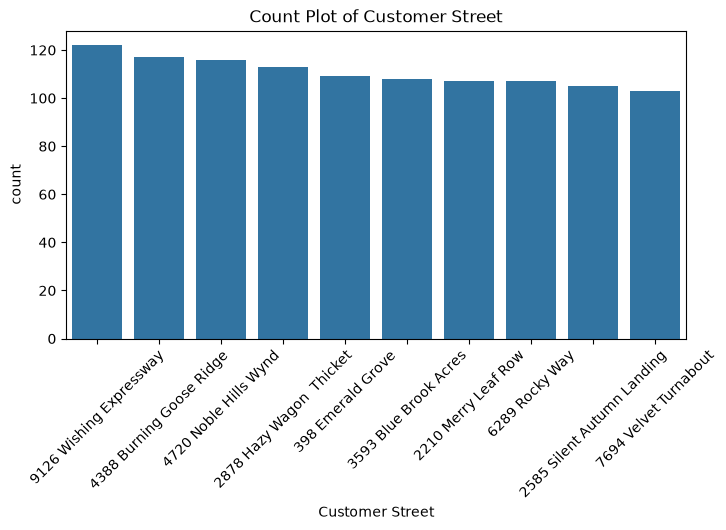

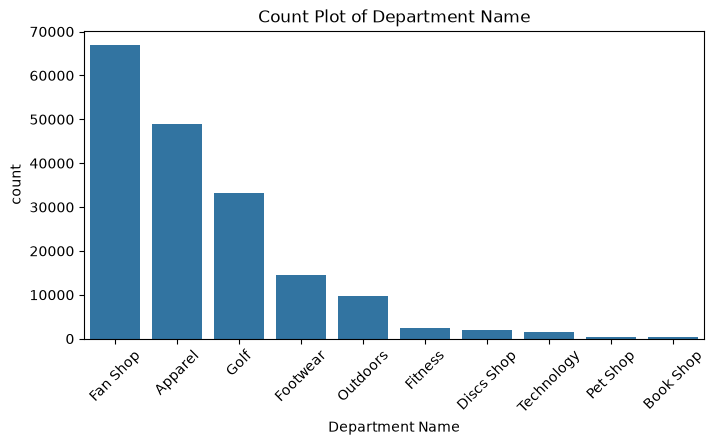

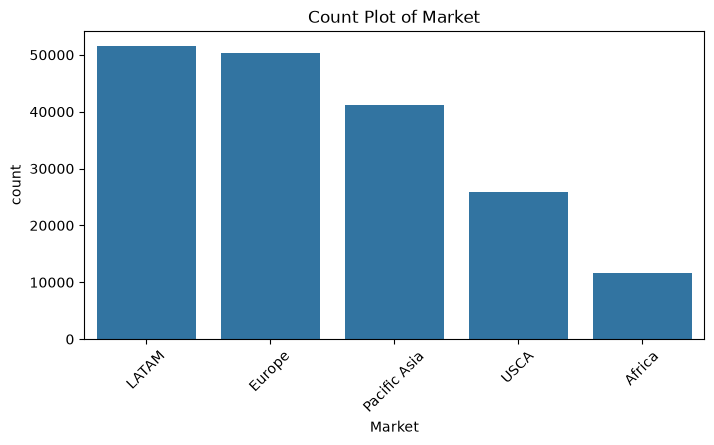

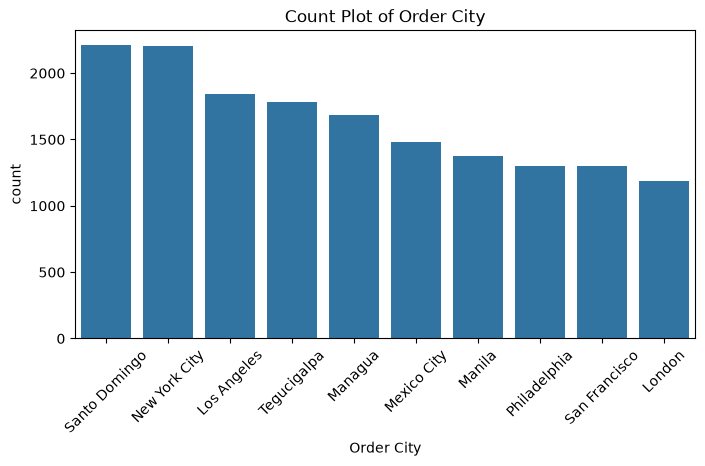

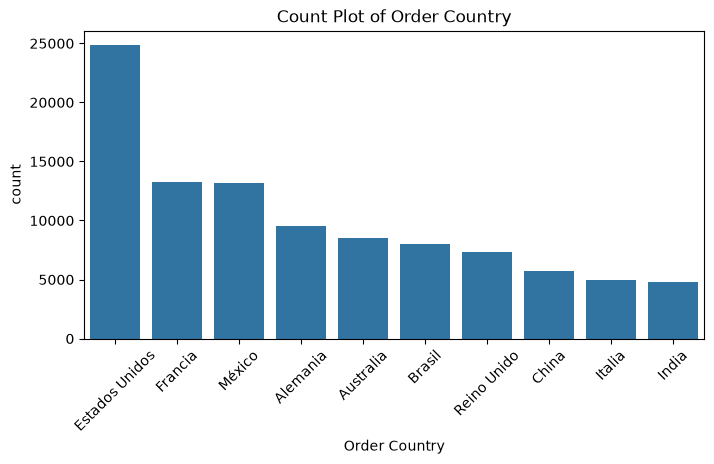

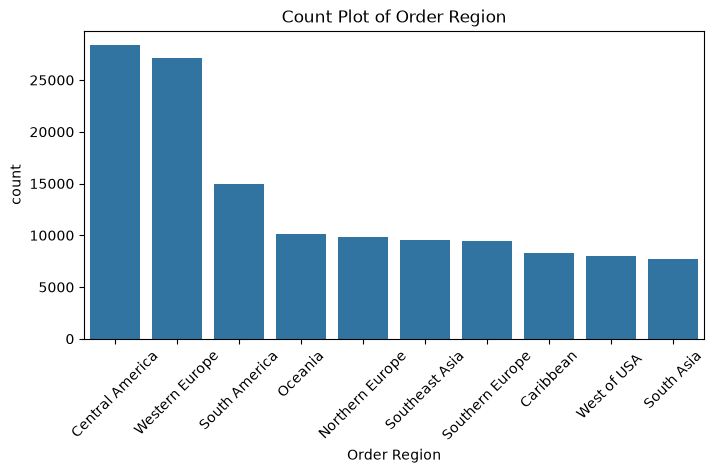

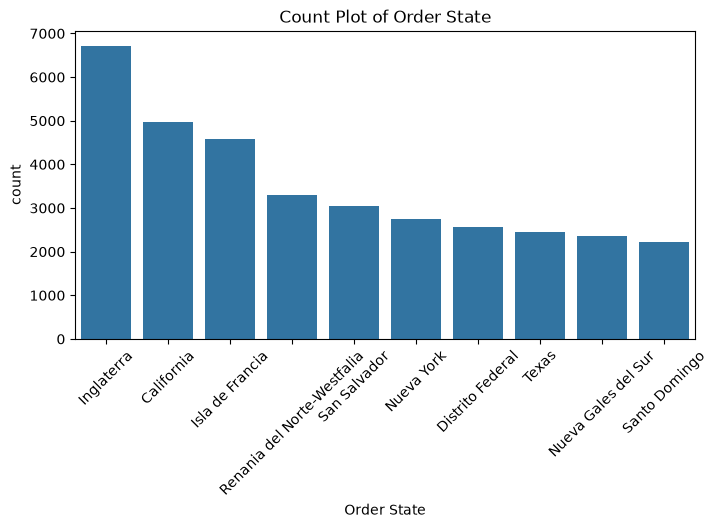

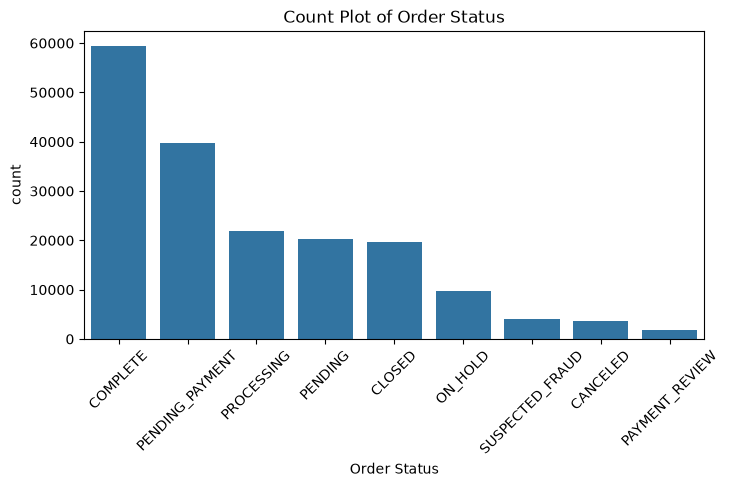

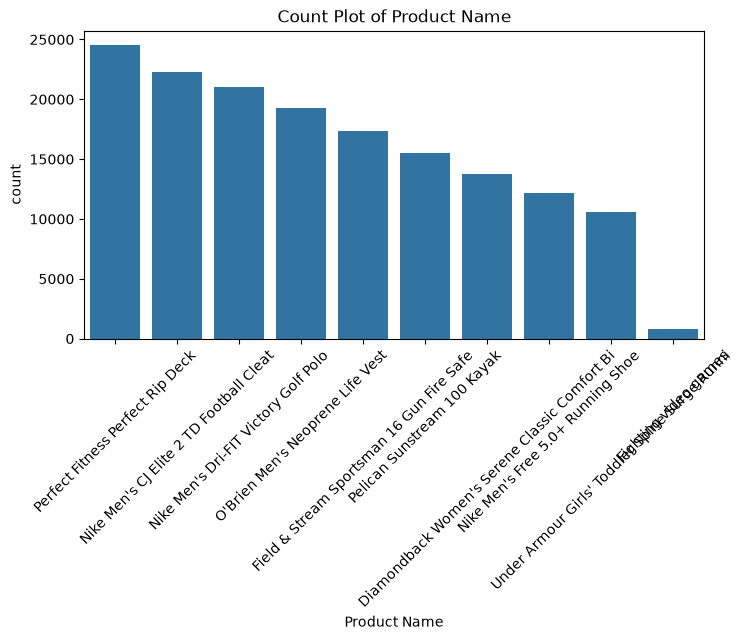

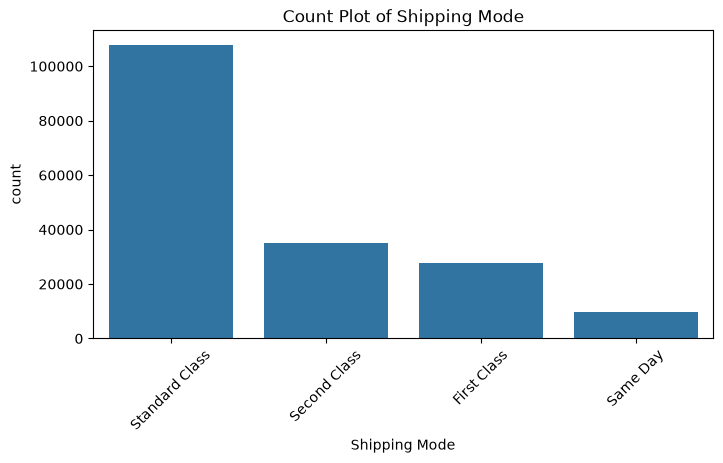

In [93]:
# Categorical Columns

for col in categorical_cols:
    plt.figure(figsize=(8,4))
    sns.countplot(
        data=df_new,
        x=col,
        order=df_new[col].value_counts().head(10).index
    )

    plt.title(f'Count Plot of {col}')
    plt.xticks(rotation=45)
    
    plt.show()


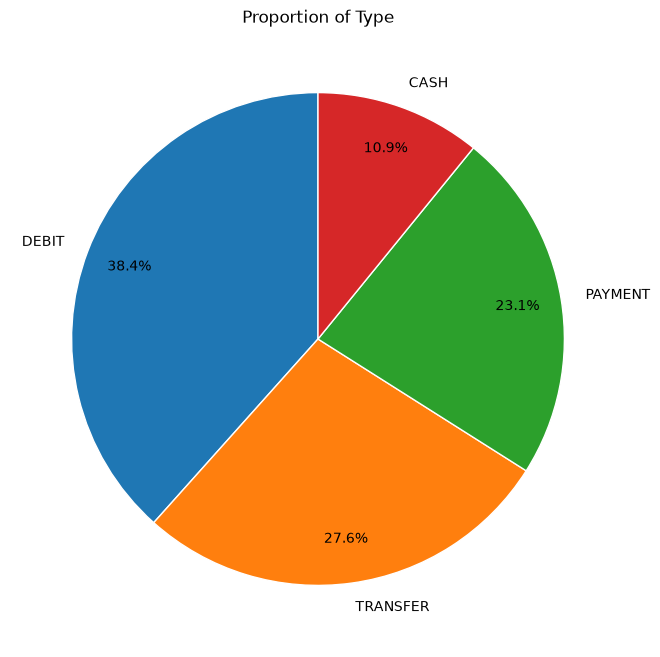

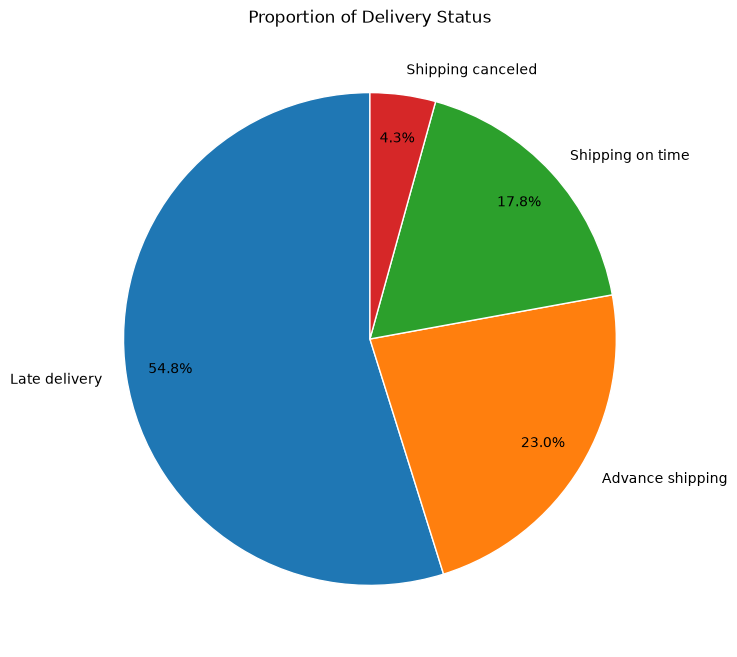

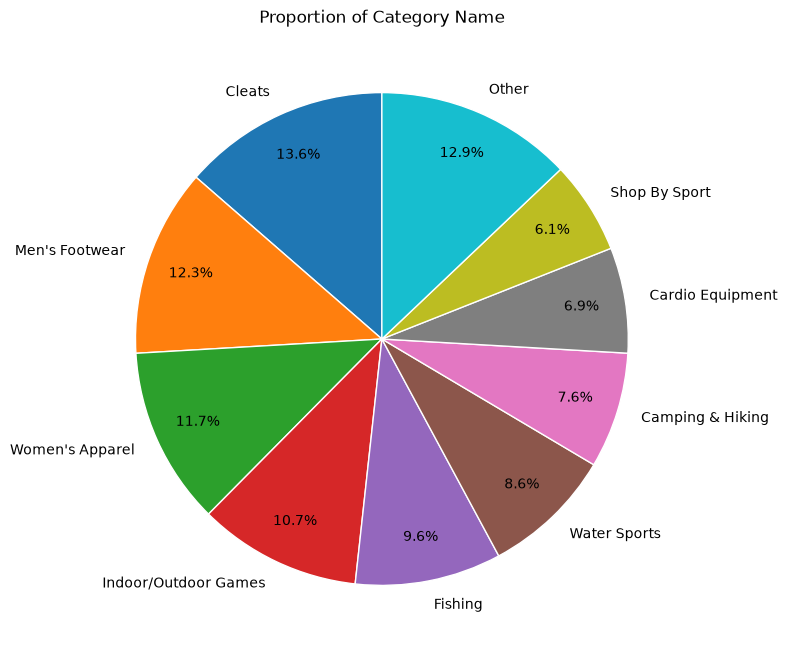

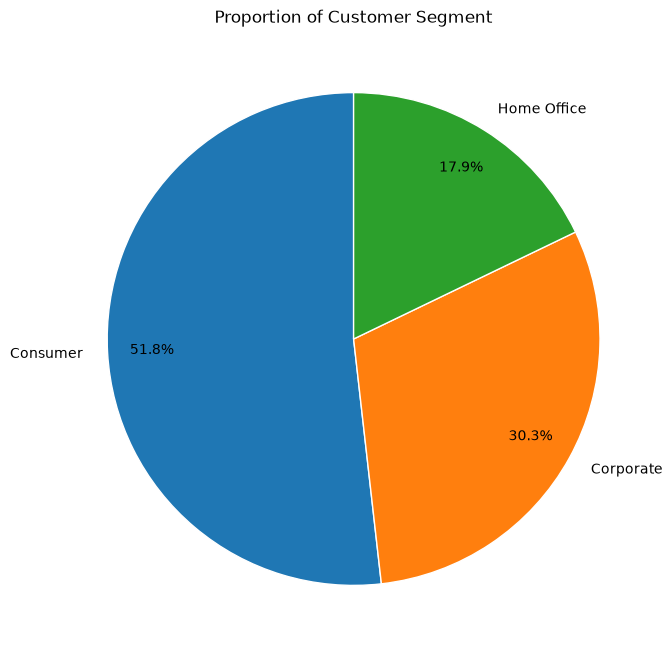

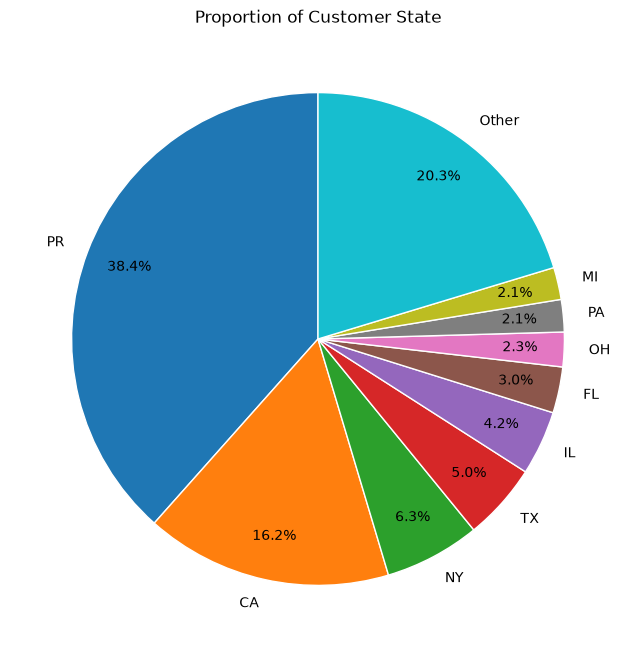

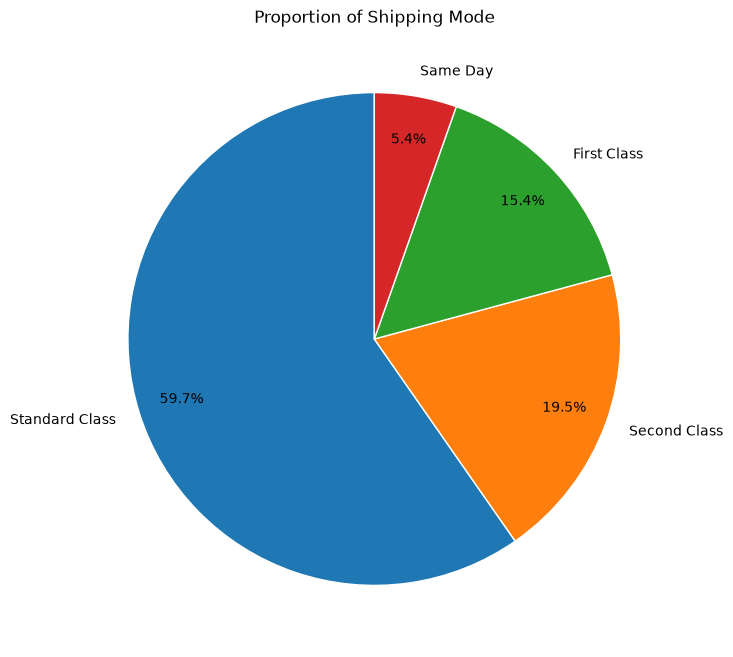

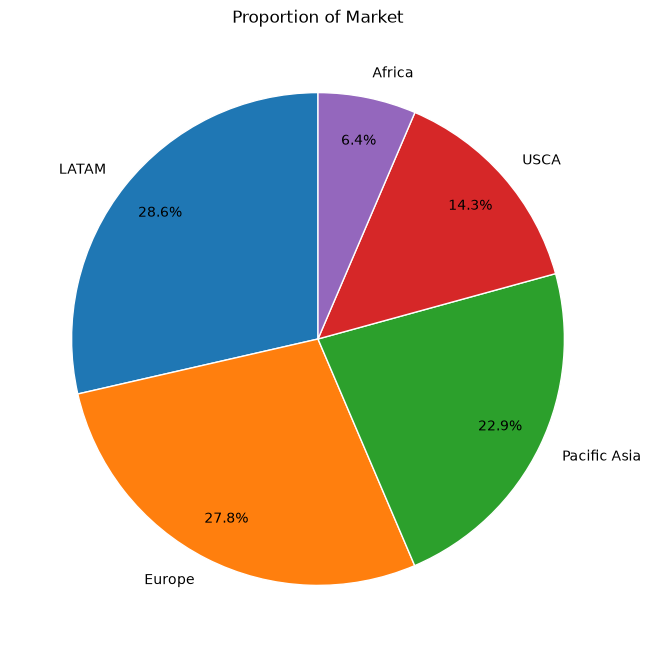

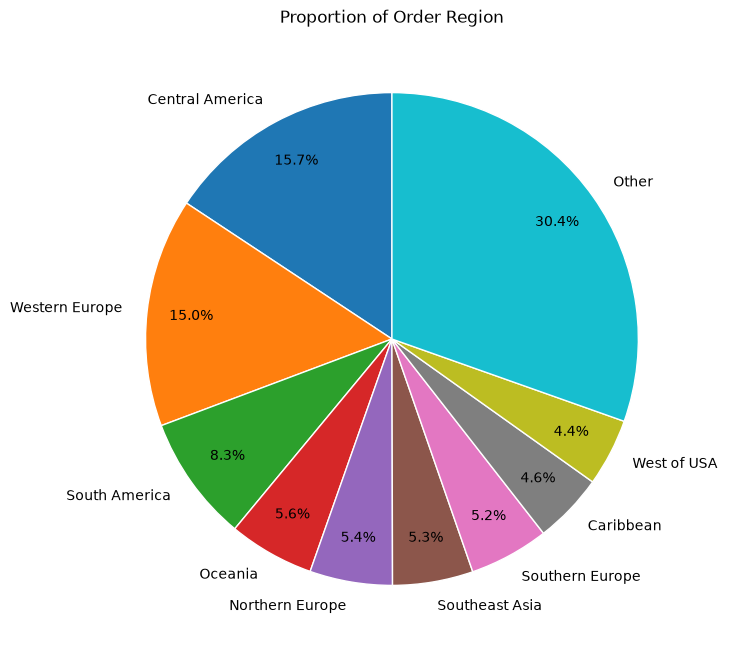

In [94]:
# Pie Plot

categorical_cols1 = ['Type','Delivery Status','Category Name','Customer Segment','Customer State','Shipping Mode','Market','Order Region']
for col in categorical_cols1:
    plt.figure(figsize=(8,8))
    counts  = df_new[col].value_counts()

    if len(counts)>10:
        top_counts = counts.head(9)
        other_sum = pd.Series({'Other':counts.iloc[9:].sum()})
        counts = pd.concat([top_counts,other_sum])

        
    counts.plot(kind='pie',autopct='%1.1f%%',startangle=90,pctdistance=0.82,wedgeprops={'edgecolor': 'white', 'linewidth': 1})
    plt.title(f'Proportion of {col}')
    plt.ylabel('')
    plt.show()

### Bivariate Analysis

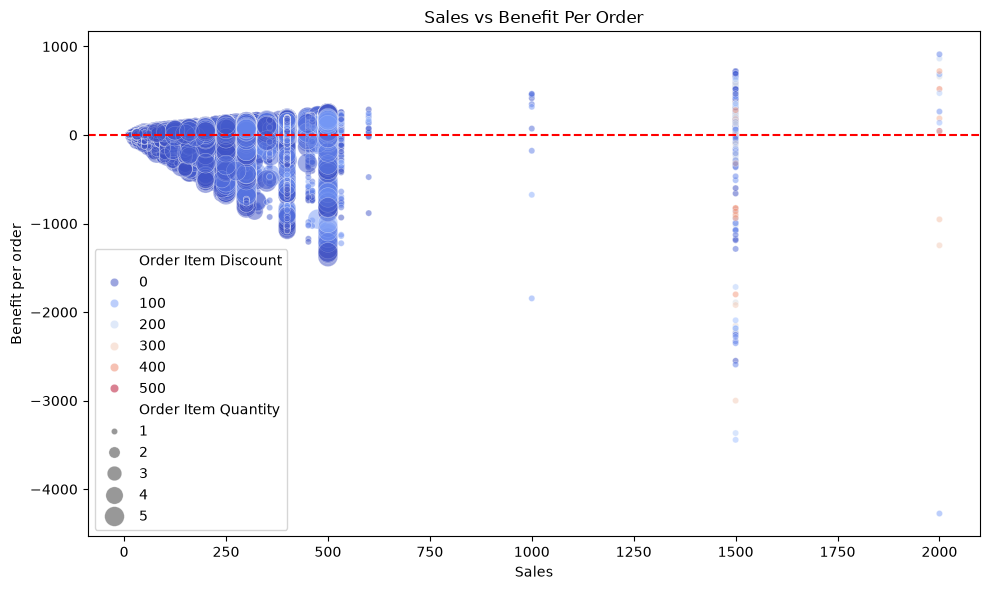

In [95]:
# Trying to find Sales,quantity and profit relationships

# Sales vs Benefit per order 

plt.figure(figsize=(10,6))
sns.scatterplot(data=df_new,x="Sales",y="Benefit per order",hue="Order Item Discount",size="Order Item Quantity",sizes=(20,200),alpha=0.5,palette="coolwarm")

plt.axhline(0,color="red",linestyle='--',linewidth=1.5,label="Break-even Level")
plt.title("Sales vs Benefit Per Order")
plt.tight_layout()
plt.show()

While the overall portfolio generates positive net returns (~81% of order items are profitable), profitability is highly uneven across price tiers and vulnerable to severe downside outliers:
- High-Volume Core ($0–$550): This tier accounts for the vast majority of transaction volume. Although most items generate steady, modest profits (up to ~$350–$450 per item), individual loss outliers still drop as low as -$1,500, showing that high sales volume alone does not eliminate margin leakage.
- High-Risk Mid-Premium Tier ($1,500): Despite low unit volume, this price bracket experiences the steepest financial losses, plunging past -$3,500 per item. Heavy discounting fails to drive profitable volume here and instead compounds negative margins.
- Top-Tier Premium SKUs ($2,000): High-end items generate positive returns but represent a very small fraction of total units sold, limiting their overall impact on bottom-line growth.

C:\Users\Rahul\AppData\Local\Temp\ipykernel_34056\591878140.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_new,x="Order Item Quantity",y="Sales",palette="Blues_d")


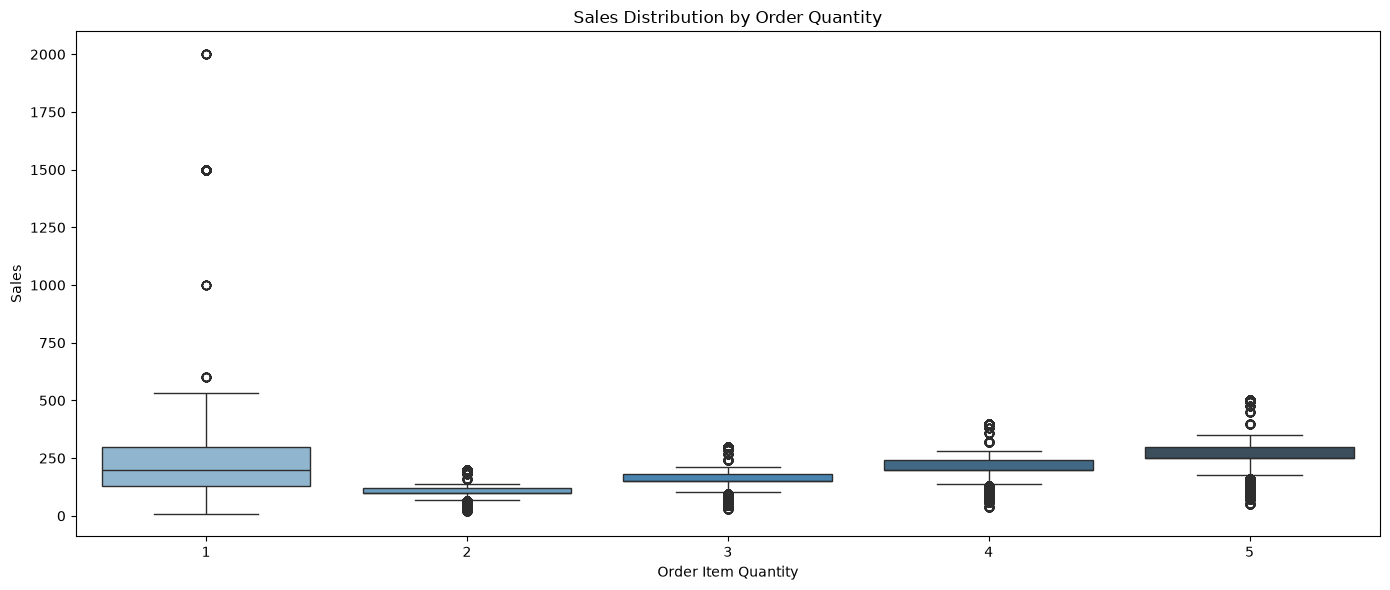

In [96]:
# Quantity vs Saless

plt.subplots(figsize=(14, 6))
sns.boxplot(data=df_new,x="Order Item Quantity",y="Sales",palette="Blues_d")

plt.title("Sales Distribution by Order Quantity")
plt.tight_layout()
plt.show()

Comparing line-item sales across order quantities reveals a clear distinction between everyday bulk purchases and high-ticket single-item orders:
- Multi-Unit Orders (Quantities 2–5): These orders consist primarily of lower-priced, everyday goods. As expected, median sales rise steadily as order quantity increases from 2 to 5 units.
- Single-Unit Premium Orders (Quantity 1): High-cost SKUs ($1,000 to $2,000+) are purchased exclusively as single units. Cross-referencing this with the profitability analysis confirms that steep financial losses are driven primarily by single-unit purchases of high-ticket items rather than bulk orders.

C:\Users\Rahul\AppData\Local\Temp\ipykernel_34056\2293877049.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


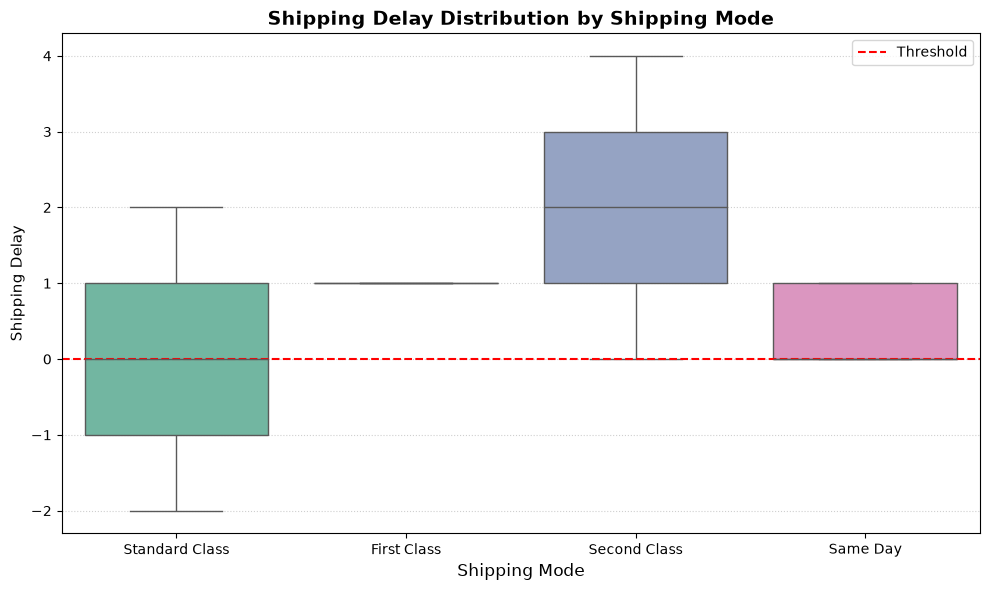

In [97]:
# Shipping Mode vs Delay

df_new['Shipping_delay'] = (df_new['Days for shipping (real)'] - df_new['Days for shipment (scheduled)'])

df_new[['Shipping_delay']]

plt.figure(figsize=(10,6))

sns.boxplot(
    data=df_new,
    x="Shipping Mode",
    y="Shipping_delay",
    palette='Set2',
    showfliers=True
)

plt.axhline(y=0,color='red',linestyle='--',linewidth=1.5,label="Threshold")

plt.title('Shipping Delay Distribution by Shipping Mode', fontsize=14, fontweight='bold')
plt.xlabel('Shipping Mode', fontsize=12)
plt.ylabel('Shipping Delay', fontsize=11)
plt.legend()
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

Delivery reliability varies significantly across shipping tiers, highlighting operational bottlenecks in expedited and mid-tier fulfillment:
- Standard Class (Most Balanced): With a median delay of 0 days, 50% of orders arrive on time or up to 2 days early, while the remaining half experience minor delays of 1 to 2 days.
- Same Day (High Reliability): Delay spans strictly from 0 to 1 day with the median at 0, confirming that orders arrive either on schedule or at most 1 day late.
- First Class (Consistent Minor Delay): The distribution compresses entirely at the 1-day mark, indicating that First Class shipments consistently miss their target window by exactly 1 day.
- Second Class (Critical Bottleneck): Second Class is the worst-performing tier. Over 75% of orders arrive 1 to 4 days late, and virtually no shipments arrive ahead of schedule.

       Category Name  Total_Profit  Total_sales  Avg_Profit  Profit_Margin_%
             Fishing 756220.767190 6.929654e+06   43.649106        10.912822
              Cleats 494636.919791 4.431943e+06   20.147323        11.160724
    Camping & Hiking 427455.568106 4.118426e+06   31.135230        10.379101
    Cardio Equipment 383011.098485 3.694843e+06   30.672788        10.366099
     Women's Apparel 350421.029567 3.147800e+06   16.658951        11.132252
        Water Sports 325146.960038 3.113845e+06   20.923228        10.441977
Indoor/Outdoor Games 318451.430554 2.888994e+06   16.501784        11.022918
      Men's Footwear 311902.820214 2.891758e+06   14.020625        10.785925
       Shop By Sport 129813.960315 1.309522e+06   11.818460         9.913079
           Computers  69656.810171 6.630000e+05  157.594593        10.506306
         Electronics  40891.379918 3.710346e+05   12.956711        11.020906
              Garden  33443.010106 2.577687e+05   69.097128        12.974037

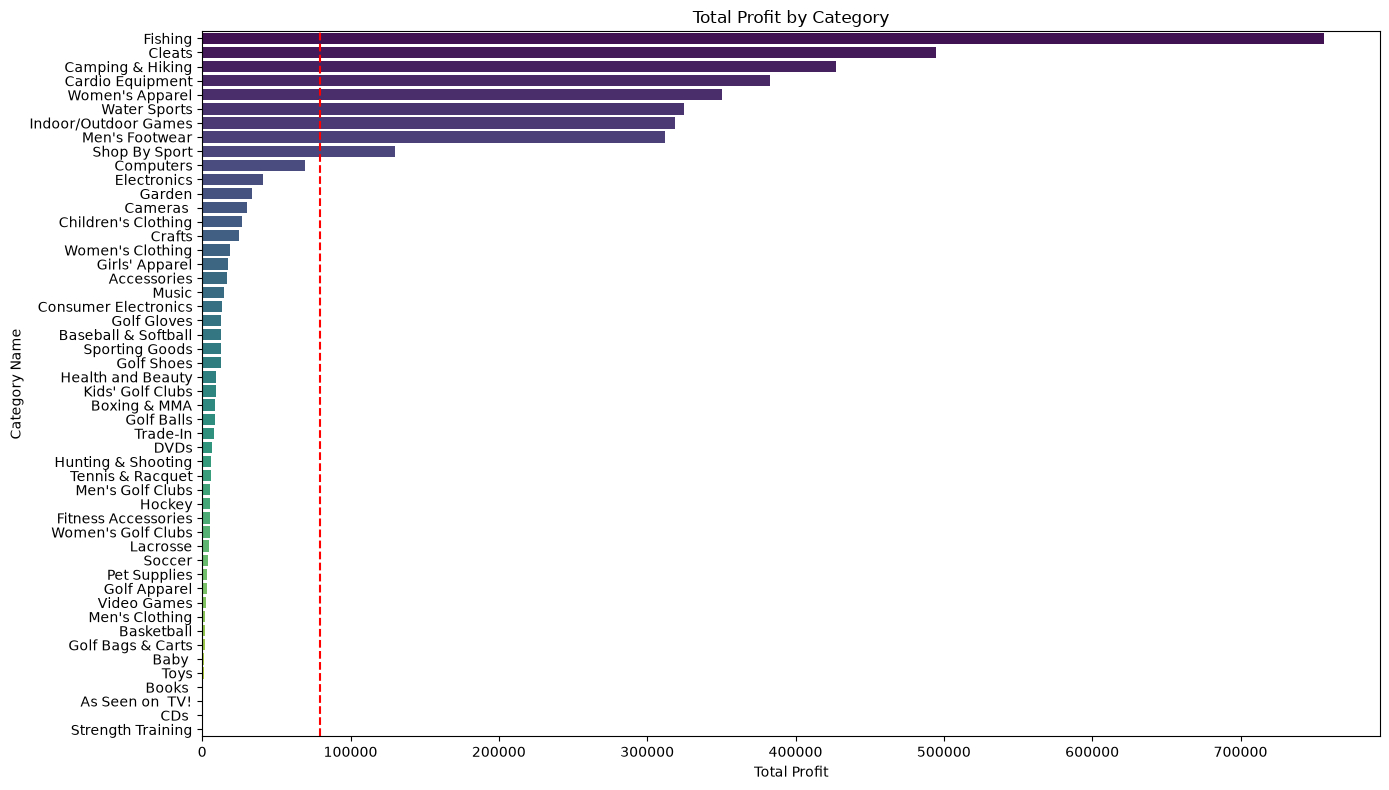

In [98]:
# Categories that are profitable

plt.figure(figsize=(14,8))

cat_profit = (
    df_new.groupby('Category Name')
    .agg(
        Total_Profit=('Benefit per order','sum'),
        Total_sales=('Sales','sum'),
        Avg_Profit = ('Benefit per order','mean'),
    ).reset_index()
)

# Calculate Profit Margin(%)

cat_profit['Profit_Margin_%'] = (
    cat_profit['Total_Profit'] / cat_profit['Total_sales']
) * 100

cat_profit = cat_profit.sort_values(by='Total_Profit',ascending=False)

print(cat_profit.to_string(index=False))


sns.barplot(data=cat_profit, x='Total_Profit', y='Category Name',hue='Category Name', legend=False,palette='viridis')
plt.title('Total Profit by Category')
plt.xlabel('Total Profit')
plt.ylabel('Category Name')
plt.axvline(cat_profit["Total_Profit"].mean(), color='red', linestyle='--')  
plt.tight_layout()
plt.show()

Top 10 Categories have majority Sales than the other categories, thus we should prioritze inventory availablility and supply chain stability for the top 10 categories.
- We need to increase the marketing and more selling of computers(157$ avg profit) and garden(69$ avg profit and 13% margin) to boost order volume.
- Audit underperfomers like strength training(0.61% margin) and as seen on tv!(3.47% margin).

In [99]:
bins = [-float('inf'),-100,0,50,150,float('inf')]
labels = ['Heavy Loss (< -100)', 'Moderate Loss (-100 to 0)', 'Low Profit (0 to 50)', 'Medium Profit (50 to 150)', 'High Profit (> 150)']

df_new['Benefit_bin'] = pd.cut(df_new['Benefit per order'],bins=bins,labels=labels)

item_counts = df_new['Benefit_bin'].value_counts().sort_index()
print(item_counts)

order_level = df_new.groupby('Order Id')['Benefit per order'].sum().reset_index()
order_level['Order_Benefit_bin'] = pd.cut(order_level['Benefit per order'],bins=bins,labels=labels)
unique_order_counts = order_level['Order_Benefit_bin'].value_counts().sort_index()
print("\nUnique Order Counts:\n", unique_order_counts)

Benefit_bin
Heavy Loss (< -100)          11539
Moderate Loss (-100 to 0)    23420
Low Profit (0 to 50)         82755
Medium Profit (50 to 150)    57430
High Profit (> 150)           5364
Name: count, dtype: int64

Unique Order Counts:
 Order_Benefit_bin
Heavy Loss (< -100)           7280
Moderate Loss (-100 to 0)     6748
Low Profit (0 to 50)         13479
Medium Profit (50 to 150)    20487
High Profit (> 150)          17747
Name: count, dtype: int64


This shows that the company is 81% profitable

   Order Region  Total_Sales  Total_Profit  Order_Count  Profit_Margin
 Western Europe 5.893666e+06 625221.870549        10008      10.608369
Central America 5.665712e+06 616341.570651         9396      10.878448
  South America 2.960881e+06 335154.400817         4979      11.319413
Northern Europe 2.155012e+06 233176.920643         3714      10.820214
Southern Europe 2.047666e+06 230746.689882         3542      11.268766
        Oceania 2.016654e+06 201478.020484         4362       9.990707
 Southeast Asia 1.931526e+06 211230.689785         4352      10.935950
      Caribbean 1.651019e+06 171825.640024         2806      10.407246
   West of USA  1.571416e+06 164940.660455         2667      10.496308
     South Asia 1.553465e+06 165688.850124         3334      10.665759
   Eastern Asia 1.485940e+06 147215.570612         3317       9.907236
    East of USA 1.371112e+06 156263.300194         2323      11.396830
      West Asia 1.174672e+06 118815.410047         2022      10.114775
     U

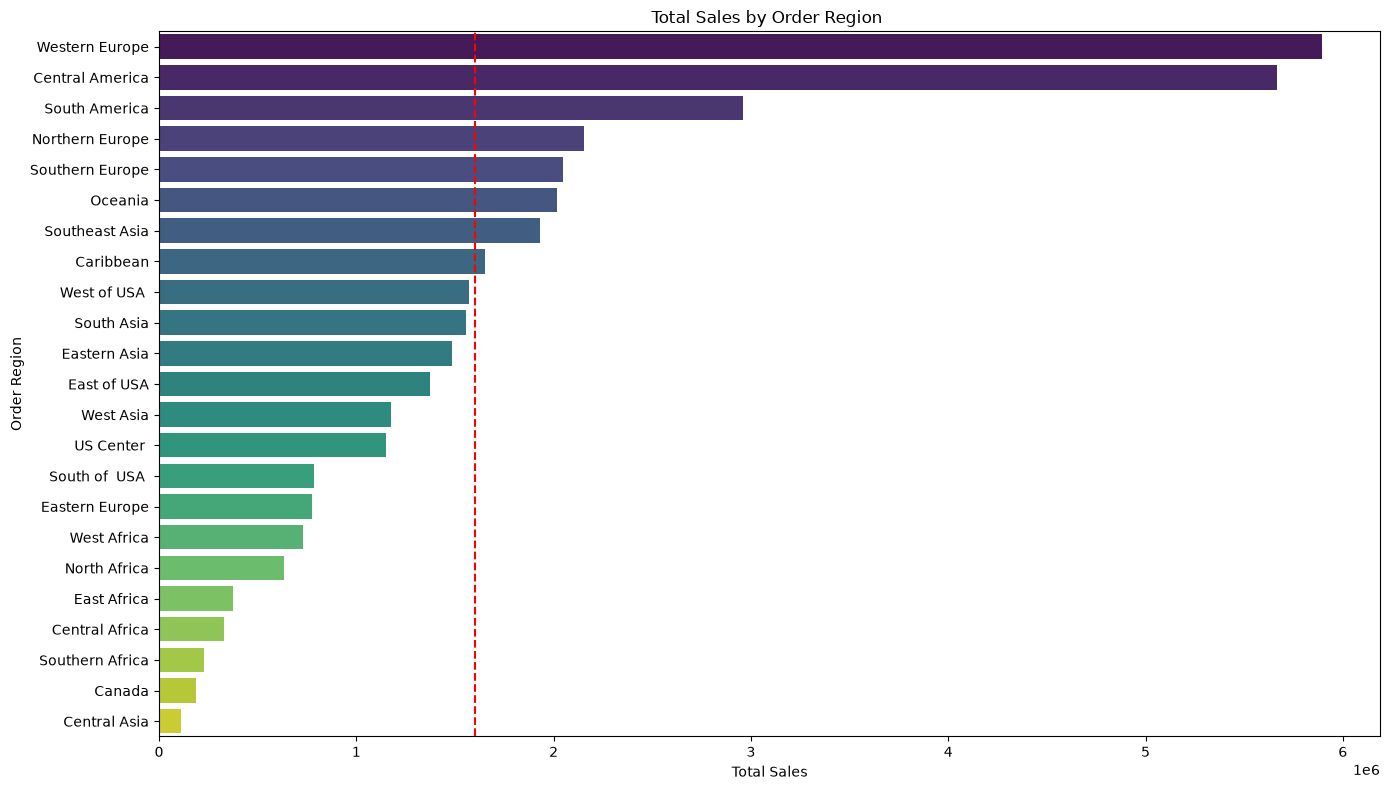

In [100]:
# Region vs Sales


plt.figure(figsize=(14,8))

region_sales = (
    df_new.groupby('Order Region')
    .agg(
        Total_Sales=('Sales','sum'),
        Total_Profit = ('Benefit per order','sum'),
        Order_Count=('Order Id','nunique'),
    )
    .reset_index()
)

# Profit Margin
region_sales['Profit_Margin'] = (
    region_sales['Total_Profit'] / region_sales['Total_Sales']
) * 100

region_sales = region_sales.sort_values(by='Total_Sales',ascending=False)

print(region_sales.to_string(index=False))

sns.barplot(data=region_sales,x='Total_Sales',y='Order Region',hue='Order Region',legend=False,palette='viridis')
plt.title('Total Sales by Order Region ')
plt.xlabel('Total Sales')
plt.ylabel('Order Region')
plt.axvline(region_sales['Total_Sales'].mean(),color='red',linestyle='--')
plt.tight_layout()
plt.show()



Global sales across DataCo Supply Chain's 23 order regions total around $36.78 million, with an average of $1.60 million per region shown by the red dashed line. Sales are heavily concentrated in Europe and Latin America, while smaller markets actually bring in the highest profit margins.
- Two Main Powerhouses: Western Europe ($5.89M) and Central America ($5.67M) lead all other regions by a huge gap. Together, they bring in $11.56M, which is nearly one-third (31.4%) of the company's total global sales and over $1.24M in profit.
- Only 8 Regions Beat the Average: Out of 23 regions, only the top 8 cross the $1.60M average line. South America ($2.96M) sits in a strong third place, followed closely by Northern Europe ($2.16M), Southern Europe ($2.05M), Oceania ($2.02M), Southeast Asia ($1.93M), and the Caribbean ($1.65M).
- The US Market is Split: At first glance, US regions look average because the country is divided into four parts (West, East, Center, and South). If you add all four together, the US makes $4.88M in total sales, making it the third-largest market overall.
- Smaller Markets Have Higher Profit Margins: High sales volume does not always mean higher efficiency. Smaller markets like Southern Africa (13.51%), Canada (12.79%), and Central Asia (11.88%) earn the highest profit margins. Meanwhile, busy regions like Oceania (9.99%) and Eastern Asia (9.91%) dip below 10%, likely due to heavier discounts or higher shipping costs.



  Delivery Status  Total_Sales  Avg_Sales  Total_Profit  Order_Count  Sales_Share%
    Late delivery 2.012486e+07 203.338875  2.139590e+06        36043     54.714907
 Advance shipping 8.516869e+06 204.786581  9.348387e+05        15124     23.155431
 Shipping on time 6.569273e+06 204.059036  7.311321e+05        11719     17.860359
Shipping canceled 1.570305e+06 202.515522  1.604823e+05         2855      4.269303


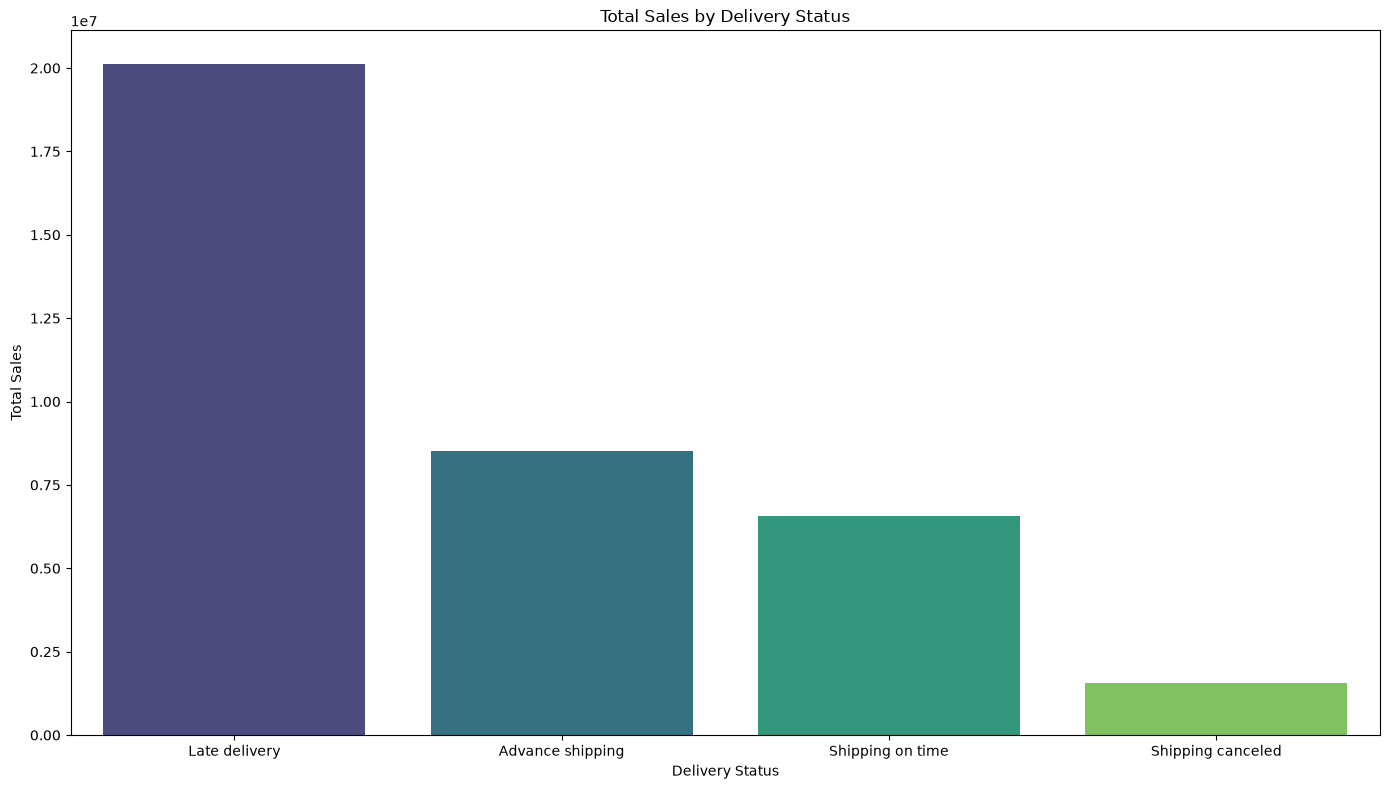

In [101]:
# Delivery Status vs Sales

delivery_sales = (
    df_new.groupby("Delivery Status")
    .agg(
        Total_Sales=("Sales","sum"),
        Avg_Sales=('Sales', 'mean'),
        Total_Profit=('Benefit per order', 'sum'),
        Order_Count=('Order Id', 'nunique')
    )
    .reset_index()
    .sort_values(by="Total_Sales",ascending=False)
)

delivery_sales["Sales_Share%"] = (
    delivery_sales["Total_Sales"] / delivery_sales["Total_Sales"].sum()
) * 100

print(delivery_sales.to_string(index=False))

plt.figure(figsize=(14,8))

sns.barplot(data=delivery_sales,
            x="Delivery Status",
            y="Total_Sales",
            hue="Delivery Status",
            palette='viridis',
            legend=False
)
plt.title('Total Sales by Delivery Status')
plt.xlabel('Delivery Status')
plt.ylabel('Total ' \
'Sales')
plt.tight_layout()
plt.show()
 

More than half of the orders are late deliveries, revealing a widespread bottleneck. The Avg Sales is 200$ for each thus, this bottleneck affects all the orders, be it high value order or low value order.

- **Majority of Revenue is Delayed:** **Late delivery** dominates all categories with **$20.12M** in sales across **36,043 orders** (**54.71%** of total revenue), putting over **$2.14M** in profit at risk of customer dissatisfaction.
- **Less Than Half Ship on Schedule:** Combined, **Advance shipping ($8.52M / 23.16%)** and **Shipping on time ($6.57M / 17.86%)** account for **41.02%** of total sales.
- **Order Size is Not the Cause:** Average order sales remain flat across all statuses ranging narrowly between **$202.52** (canceled) and **$204.79** (advance shipping) proving that large order sizes do not trigger shipping delays.
- **Canceled Orders Cost $1.57M:** **Shipping canceled** accounts for **4.27%** of total volume (**2,855 orders**) and shows the lowest profit margin (**10.22%**) compared to on-time shipments (**11.13%**).

### Multivariate Analysis

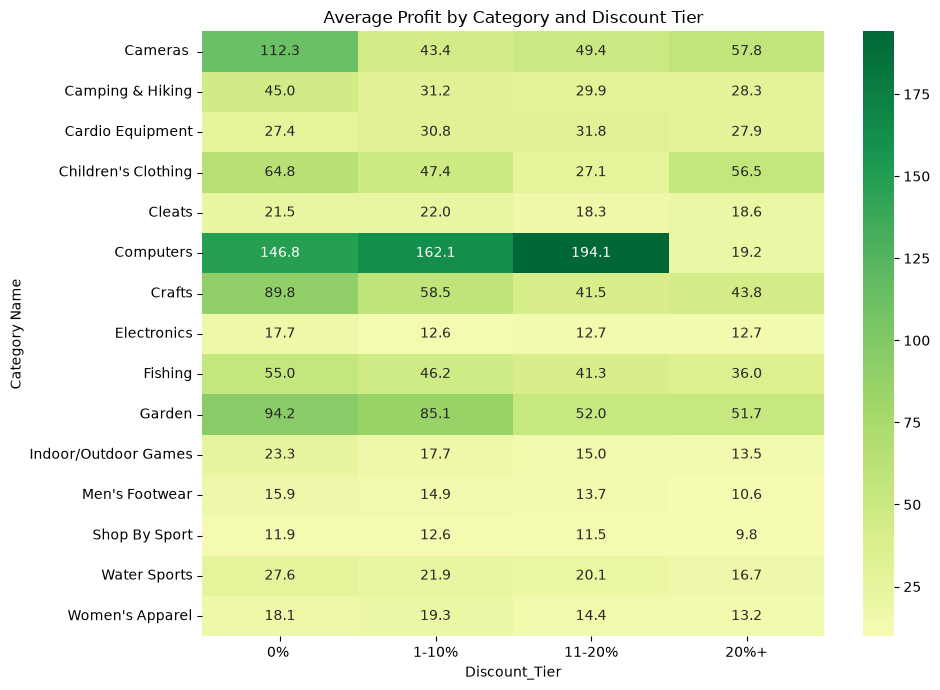

In [102]:
# Which Category suffers in profit when discount is applied
df_new['Discount_Tier'] = pd.cut(
    df_new['Order Item Discount Rate'] * 100,
    bins=[-1, 0, 10, 20, 100],
    labels=['0% ', '1-10%', '11-20%', '20%+']
)

# top 15 categories by sales for a clean heatmap
top_cats = df_new.groupby('Category Name')['Sales'].sum().nlargest(15).index

disc_cat = (
    df_new[df_new['Category Name'].isin(top_cats)]
    .pivot_table(
        index='Category Name',
        columns='Discount_Tier',
        values='Benefit per order',
        aggfunc='mean',
        observed=False
    )
)

plt.figure(figsize=(10, 7))
sns.heatmap(disc_cat, annot=True, fmt='.1f', cmap='RdYlGn', center=0)
plt.title('Average Profit by Category and Discount Tier')
plt.tight_layout()
plt.show()

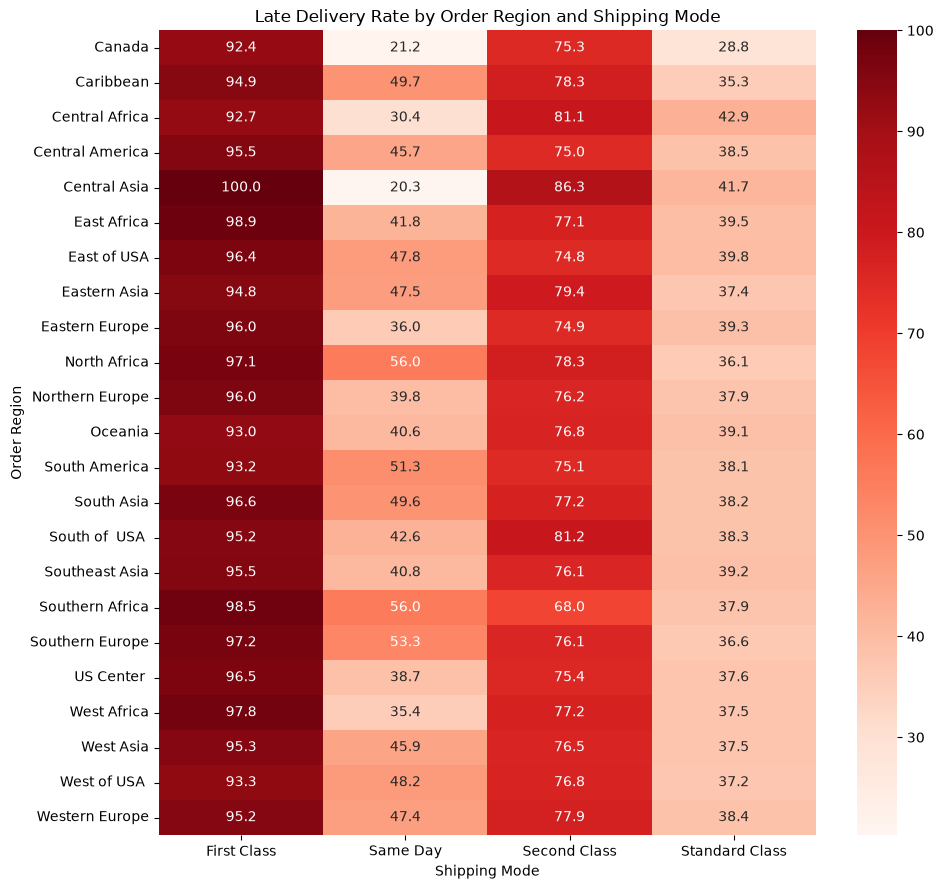

In [103]:
# Late Delivery Risk for every combination of order region and shipping mode
df_new['Is_Late'] = (df_new['Delivery Status'] == 'Late delivery').astype(int)

reg_ship_delay = (
    df_new.pivot_table(
        index='Order Region',
        columns='Shipping Mode',
        values='Is_Late',
        aggfunc='mean'
    ) * 100
)

plt.figure(figsize=(10, 9))
sns.heatmap(reg_ship_delay, annot=True, fmt='.1f', cmap='Reds')
plt.title('Late Delivery Rate by Order Region and Shipping Mode')
plt.tight_layout()
plt.show()


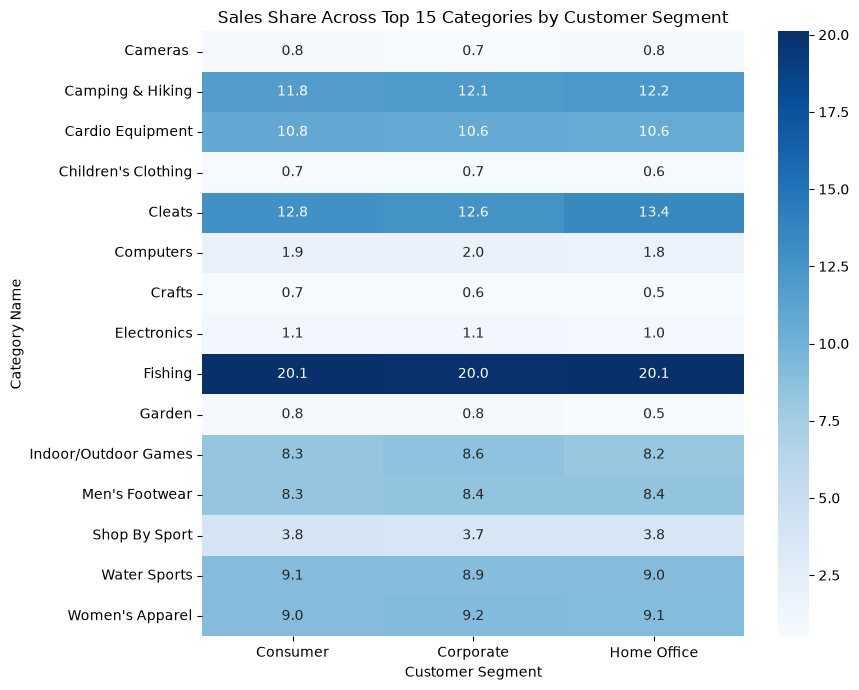

In [104]:
# Purchasing preference among the customer segments
seg_cat = (
    df_new[df_new['Category Name'].isin(top_cats)]
    .pivot_table(
        index='Category Name',
        columns='Customer Segment',
        values='Sales',
        aggfunc='sum'
    )
)

# Normalize by column to see each segment's % share across categories
seg_cat_pct = seg_cat.div(seg_cat.sum(axis=0), axis=1) * 100

plt.figure(figsize=(9, 7))
sns.heatmap(seg_cat_pct, annot=True, fmt='.1f', cmap='Blues')
plt.title('Sales Share Across Top 15 Categories by Customer Segment')
plt.tight_layout()
plt.show()


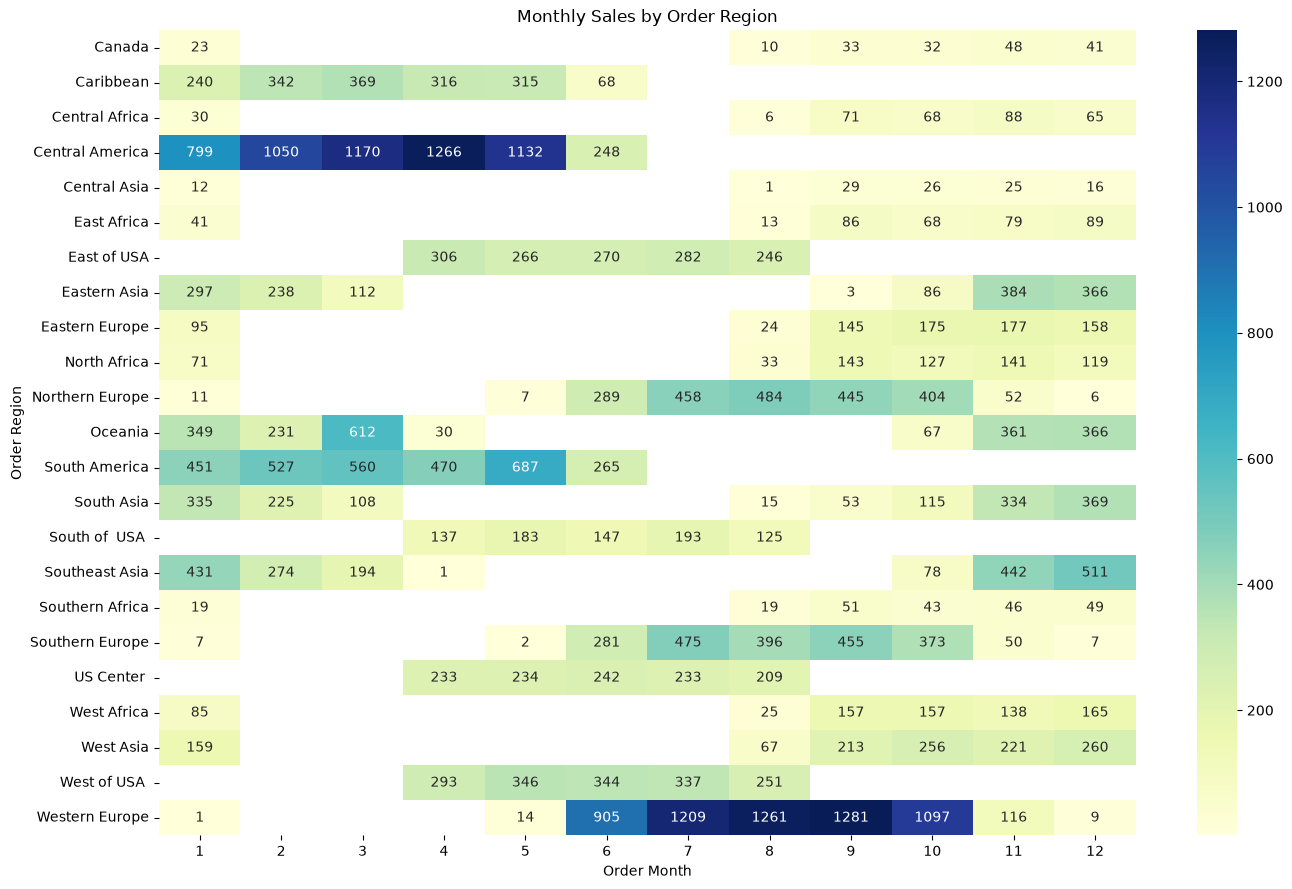

In [105]:
# Sales for Order Month for order regions 
df_new['Order_Date_Parsed'] = pd.to_datetime(df_new['order date (DateOrders)'])
df_new['Order_Month'] = df_new['Order_Date_Parsed'].dt.month

month_reg = (
    df_new.pivot_table(
        index='Order Region',
        columns='Order_Month',
        values='Sales',
        aggfunc='sum'
    ) / 1e3  
)

plt.figure(figsize=(14, 9))
sns.heatmap(month_reg, annot=True, fmt='.0f', cmap='YlGnBu')
plt.title('Monthly Sales by Order Region')
plt.xlabel('Order Month')
plt.tight_layout()
plt.show()


 Shipping Mode       Market  Avg_Real_Shipping_Days  Late_Delivery_Rate_Pct  Order_Count
   First Class       Africa                2.000000               96.988998          557
   First Class       Europe                2.000000               95.818021         2877
   First Class         USCA                2.000000               95.159681         1338
   First Class Pacific Asia                2.000000               95.079365         2667
   First Class        LATAM                2.000000               94.737510         2638
      Same Day        LATAM                0.510943               48.037736          913
      Same Day       Europe                0.486046               46.429866          999
      Same Day         USCA                0.451185               44.421199          466
      Same Day       Africa                0.474551               44.011976          234
      Same Day Pacific Asia                0.448338               43.530997          959
  Second Class       

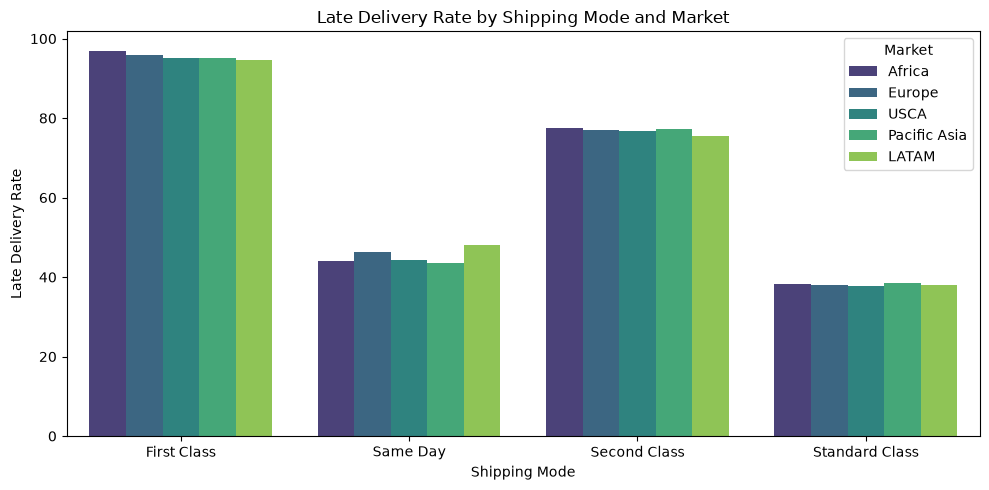

In [106]:
# Late Delivery Risk for Regions
group_col = 'Order Priority' if 'Order Priority' in df_new.columns else 'Market'

prio_ship = (
    df_new.groupby(['Shipping Mode', group_col])
    .agg(
        Avg_Real_Shipping_Days=('Days for shipping (real)', 'mean'),
        Late_Delivery_Rate_Pct=('Is_Late', lambda x: x.mean() * 100),
        Order_Count=('Order Id', 'nunique')
    )
    .reset_index()
    .sort_values(by=['Shipping Mode', 'Late_Delivery_Rate_Pct'], ascending=[True, False])
)

print(prio_ship.to_string(index=False))

plt.figure(figsize=(10, 5))
sns.barplot(
    data=prio_ship,
    x='Shipping Mode',
    y='Late_Delivery_Rate_Pct',
    hue=group_col,
    palette='viridis'
)
plt.title(f'Late Delivery Rate by Shipping Mode and {group_col}')
plt.ylabel('Late Delivery Rate')
plt.tight_layout()
plt.show()



Comparing actual transit days against late delivery rates across all five global markets reveals that DataCo's delivery failures stem from **broken shipping tier execution** rather than regional bottlenecks. Specifically, **Second Class** and **Standard Class** take the exact same amount of time to deliver (~4.0 days), causing widespread late deliveries for premium-paying customers.


- **Second Class Matches Standard Class Speed:** Across every market, **Second Class** averages **3.98 to 4.00 real shipping days**, which is identical to **Standard Class** (**3.99 to 4.02 days**). Because Second Class promises a 2-day delivery window, **75.6% to 77.4%** of those **12,776 orders** arrive late.
- **First Class Consistently Misses Its 1-Day Target:** **First Class** averages exactly **2.00 real shipping days** across all 5 markets (**10,077 orders**), resulting in a **94.7% to 97.0%** late delivery rate globally.
- **Same Day Splits Evenly Between Day 0 and Day 1:** **Same Day** orders (**3,571 orders**) average **0.45 to 0.51 real shipping days**, leaving **43.5% to 48.0%** of orders delayed by one day.
- **Standard Class is the Most Reliable Tier:** Handling the largest volume (**39,319 orders**), **Standard Class** maintains the lowest late delivery rate (**37.9% to 38.5%**) because its 4-day promised window aligns with actual warehouse transit times.



### Correlation Analysis


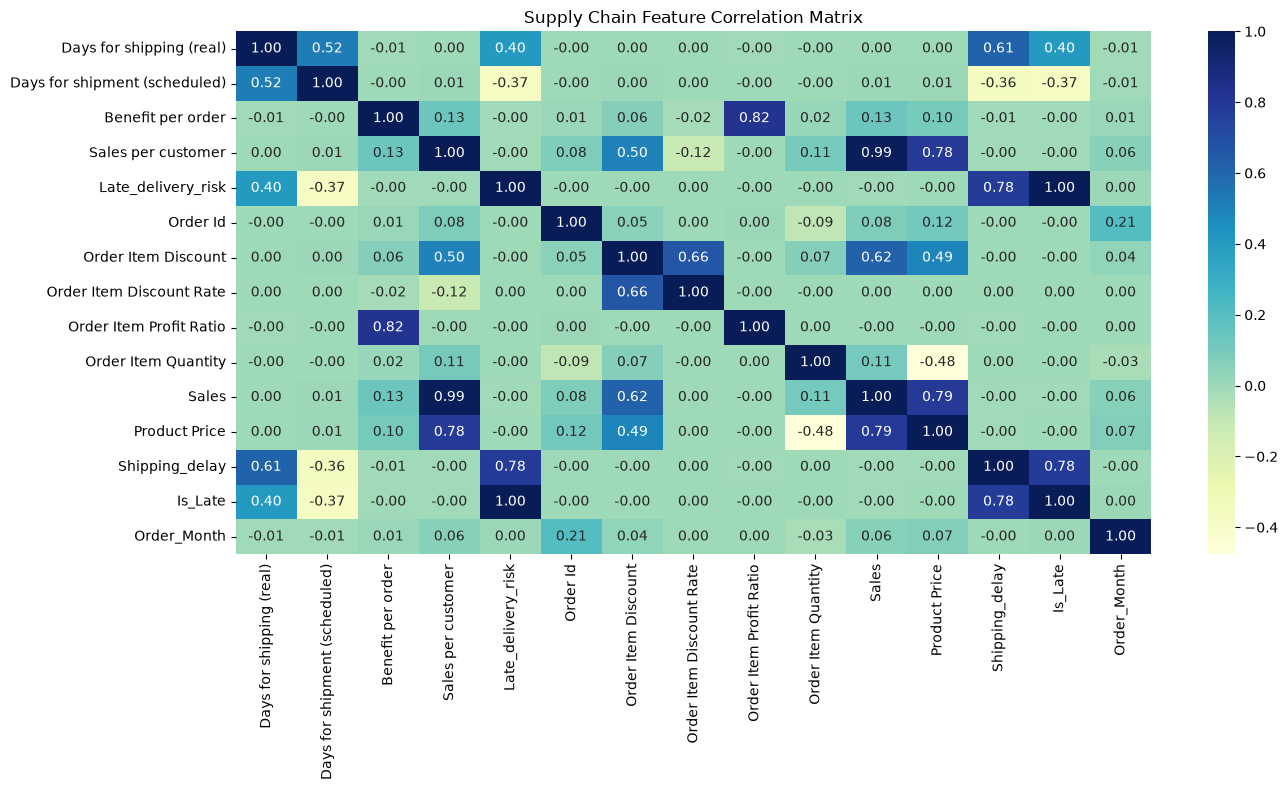

In [107]:

corr = df_new.corr(numeric_only=True)

plt.figure(figsize=(14,8))
sns.heatmap(corr, annot=True, cmap='YlGnBu',fmt='1.02f')
plt.title('Supply Chain Feature Correlation Matrix')
plt.tight_layout()
plt.show()